In [1]:

import pandas as pd
from pathlib import Path

csv_path = Path("conveyor_historian_raw.csv")

df_raw = pd.read_csv(csv_path)

print("Shape:", df_raw.shape)
print("\nColumns:")
print(df_raw.columns.tolist())

print("\nFirst 10 rows:")
display(df_raw.head(10))

print("\nReadings per tag:")
display(
    df_raw.groupby("tagName")
    .agg(
        readings=("value", "size"),
        missing_values=("value", lambda s: s.isna().sum()),
        unique_timestamps=("timestamp", "nunique")
    )
    .sort_index()
)

print("\nTimestamp range:")
print("Start:", df_raw["timestamp"].min())
print("End:  ", df_raw["timestamp"].max())

print("\nDuplicate rows:", df_raw.duplicated().sum())


Shape: (297876, 3)

Columns:
['timestamp', 'tagName', 'value']

First 10 rows:


,timestamp,tagName,value
0,2026-10-17 23:01:54.524,commandedSpeed,0.0
1,2026-10-17 23:01:55.525,commandedSpeed,0.0
2,2026-10-17 23:01:56.526,commandedSpeed,0.0
3,2026-10-17 23:01:57.527,commandedSpeed,0.0
4,2026-10-17 23:01:58.527,commandedSpeed,0.0
5,2026-10-17 23:01:59.528,commandedSpeed,0.0
6,2026-10-17 23:02:00.528,commandedSpeed,0.0
7,2026-10-17 23:02:01.529,commandedSpeed,0.0
8,2026-10-17 23:02:02.529,commandedSpeed,0.0
9,2026-10-17 23:02:03.530,commandedSpeed,0.0



Readings per tag:


,readings,missing_values,unique_timestamps
tagName,,,
commandedSpeed,24823,0,24823
conveyorLoad,24823,0,24823
isMotorRunning,24823,0,24823
motorCurrent,24823,0,24823
roller_1_bearing_1_temp,24823,0,24823
roller_1_bearing_1_vibration,24823,0,24823
roller_1_bearing_2_temp,24823,0,24823
roller_1_bearing_2_vibration,24823,0,24823
roller_2_bearing_1_temp,24823,0,24823



Timestamp range:
Start: 2026-10-17 23:01:54.524
End:   2026-10-18 05:56:42.189

Duplicate rows: 0


In [2]:

# Parse timestamps while preserving millisecond precision
df_raw["timestamp"] = pd.to_datetime(
    df_raw["timestamp"],
    format="%Y-%m-%d %H:%M:%S.%f",
    errors="raise"
)

# Check how many tags recorded a value at each exact timestamp
timestamp_coverage = (
    df_raw.groupby("timestamp")["tagName"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("Number of distinct timestamps:", df_raw["timestamp"].nunique())
print("\nNumber of tags present at each timestamp:")
display(timestamp_coverage.rename_axis("number_of_tags").to_frame("timestamp_count"))

# Show timestamps where not all 12 tags have a reading
coverage_per_timestamp = (
    df_raw.groupby("timestamp")["tagName"]
    .nunique()
    .rename("tag_count")
)

incomplete_timestamps = coverage_per_timestamp[
    coverage_per_timestamp != 12
]

print("\nTimestamps with all 12 tags:", (coverage_per_timestamp == 12).sum())
print("Timestamps missing one or more tags:", len(incomplete_timestamps))

print("\nFirst 15 incomplete timestamps:")
display(incomplete_timestamps.head(15).to_frame())


Number of distinct timestamps: 24852

Number of tags present at each timestamp:


,timestamp_count
number_of_tags,
1,17
2,3
3,4
4,2
5,2
6,2
7,2
8,2
9,4



Timestamps with all 12 tags: 24794
Timestamps missing one or more tags: 58

First 15 incomplete timestamps:


,tag_count
timestamp,
2026-10-17 23:10:14.980,1
2026-10-17 23:10:14.981,11
2026-10-17 23:10:36.124,10
2026-10-17 23:10:36.125,2
2026-10-17 23:16:08.552,1
2026-10-17 23:16:08.553,11
2026-10-17 23:40:47.844,11
2026-10-17 23:40:47.845,1
2026-10-18 00:17:07.619,11


In [3]:

# Inspect the tags present at each incomplete timestamp
for ts in incomplete_timestamps.index[:15]:
    print("\nTimestamp:", ts)

    rows = df_raw.loc[
        df_raw["timestamp"] == ts,
        ["tagName", "value"]
    ]

    print(rows.to_string(index=False))

    # Check the immediately adjacent millisecond
    next_ts = ts + pd.Timedelta(milliseconds=1)

    next_rows = df_raw.loc[
        df_raw["timestamp"] == next_ts,
        ["tagName", "value"]
    ]

    if not next_rows.empty:
        print("\nAdjacent timestamp:", next_ts)
        print(next_rows.to_string(index=False))



Timestamp: 2026-10-17 23:10:14.980000
       tagName  value
commandedSpeed   0.45

Adjacent timestamp: 2026-10-17 23:10:14.981000
                     tagName     value
                conveyorLoad 14.640160
              isMotorRunning  1.000000
                motorCurrent  0.706825
     roller_1_bearing_1_temp 34.690849
roller_1_bearing_1_vibration  0.943956
     roller_1_bearing_2_temp 34.356430
roller_1_bearing_2_vibration  0.934474
     roller_2_bearing_1_temp 34.771130
roller_2_bearing_1_vibration  1.030680
     roller_2_bearing_2_temp 34.644989
roller_2_bearing_2_vibration  0.875675

Timestamp: 2026-10-17 23:10:14.981000
                     tagName     value
                conveyorLoad 14.640160
              isMotorRunning  1.000000
                motorCurrent  0.706825
     roller_1_bearing_1_temp 34.690849
roller_1_bearing_1_vibration  0.943956
     roller_1_bearing_2_temp 34.356430
roller_1_bearing_2_vibration  0.934474
     roller_2_bearing_1_temp 34.771130
roller_2_be

In [4]:

# Sort distinct timestamps
unique_times = pd.Series(
    df_raw["timestamp"].drop_duplicates().sort_values().to_numpy()
)

# Difference between consecutive timestamps
time_diffs = unique_times.diff().dropna()

print("Most common timestamp differences:")
display(
    time_diffs.value_counts().head(10).rename_axis(
        "time_difference"
    ).to_frame("count")
)

print("\nTimestamp differences in milliseconds:")
display(
    (time_diffs.dt.total_seconds() * 1000)
    .round(3)
    .value_counts()
    .sort_index()
    .head(20)
    .rename_axis("difference_ms")
    .to_frame("count")
)

# Check how many timestamps are 1 ms apart
one_ms_count = (time_diffs == pd.Timedelta(milliseconds=1)).sum()

print("\nAdjacent distinct timestamps exactly 1 ms apart:", one_ms_count)
print("Total adjacent timestamp pairs:", len(time_diffs))


Most common timestamp differences:


,count
time_difference,
0 days 00:00:01.001000,11181
0 days 00:00:01,8529
0 days 00:00:01.002000,2918
0 days 00:00:01.014000,324
0 days 00:00:01.013000,318
0 days 00:00:01.012000,261
0 days 00:00:01.015000,219
0 days 00:00:01.003000,212
0 days 00:00:01.011000,202



Timestamp differences in milliseconds:


,count
difference_ms,
1.0,29
1000.0,8529
1001.0,11181
1002.0,2918
1003.0,212
1004.0,92
1005.0,52
1006.0,59
1007.0,58



Adjacent distinct timestamps exactly 1 ms apart: 29
Total adjacent timestamp pairs: 24851


In [5]:

# Compare every tag's timestamps with the commandedSpeed timeline.

reference_tag = "commandedSpeed"

reference_times = pd.DatetimeIndex(
    df_raw.loc[
        df_raw["tagName"] == reference_tag, "timestamp"
    ].sort_values()
)

print("Reference tag:", reference_tag)
print("Reference readings:", len(reference_times))

offset_results = []

for tag in sorted(df_raw["tagName"].unique()):
    tag_times = pd.DatetimeIndex(
        df_raw.loc[
            df_raw["tagName"] == tag, "timestamp"
        ].sort_values()
    )

    # Exact matches
    exact_matches = tag_times.isin(reference_times).sum()

    # For each tag timestamp, find the nearest reference timestamp.
    # This is diagnostic only; it does not modify any reading.
    nearest_positions = reference_times.get_indexer(
        tag_times, method="nearest", tolerance=pd.Timedelta(seconds=0.1)
    )

    matched = nearest_positions >= 0
    offsets_ms = []

    for i, position in enumerate(nearest_positions):
        if position >= 0:
            offsets_ms.append(
                (tag_times[i] - reference_times[position]).total_seconds()
                * 1000
            )

    offset_results.append({
        "tagName": tag,
        "readings": len(tag_times),
        "exact_timestamp_matches": exact_matches,
        "nearest_matches_within_100ms": int(matched.sum()),
        "unmatched_within_100ms": int((~matched).sum()),
        "median_offset_ms": (
            round(float(pd.Series(offsets_ms).median()), 3)
            if offsets_ms else None
        ),
        "max_absolute_offset_ms": (
            round(float(pd.Series(offsets_ms).abs().max()), 3)
            if offsets_ms else None
        )
    })

offset_df = pd.DataFrame(offset_results)
display(offset_df)


Reference tag: commandedSpeed
Reference readings: 24823


,tagName,readings,exact_timestamp_matches,nearest_matches_within_100ms,unmatched_within_100ms,median_offset_ms,max_absolute_offset_ms
0,commandedSpeed,24823,24823,24823,0,0.0,0.0
1,conveyorLoad,24823,24809,24823,0,0.0,1.0
2,isMotorRunning,24823,24807,24823,0,0.0,1.0
3,motorCurrent,24823,24805,24823,0,0.0,1.0
4,roller_1_bearing_1_temp,24823,24804,24823,0,0.0,1.0
5,roller_1_bearing_1_vibration,24823,24802,24823,0,0.0,1.0
6,roller_1_bearing_2_temp,24823,24801,24823,0,0.0,1.0
7,roller_1_bearing_2_vibration,24823,24801,24823,0,0.0,1.0
8,roller_2_bearing_1_temp,24823,24800,24823,0,0.0,1.0
9,roller_2_bearing_1_vibration,24823,24798,24823,0,0.0,1.0


In [6]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# CONFIGURATION
# ============================================================

reference_tag = "commandedSpeed"
tolerance = pd.Timedelta(milliseconds=1)

shared_tags = [
    "isMotorRunning",
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent"
]

bearing_map = {
    "ROLLER-1BEARING-1": {
        "temp": "roller_1_bearing_1_temp",
        "vibration": "roller_1_bearing_1_vibration"
    },
    "ROLLER-1BEARING-2": {
        "temp": "roller_1_bearing_2_temp",
        "vibration": "roller_1_bearing_2_vibration"
    },
    "ROLLER-2BEARING-1": {
        "temp": "roller_2_bearing_1_temp",
        "vibration": "roller_2_bearing_1_vibration"
    },
    "ROLLER-2BEARING-2": {
        "temp": "roller_2_bearing_2_temp",
        "vibration": "roller_2_bearing_2_vibration"
    }
}

# Work on a copy; preserve the raw data
raw = df_raw.copy()
raw["timestamp"] = pd.to_datetime(
    raw["timestamp"], errors="raise"
)

# ============================================================
# CREATE REFERENCE TIMELINE
# ============================================================

reference = (
    raw.loc[raw["tagName"] == reference_tag, ["timestamp", "value"]]
    .sort_values("timestamp")
    .rename(columns={"value": "commandedSpeed"})
    .reset_index(drop=True)
)

if reference["timestamp"].duplicated().any():
    raise ValueError("Reference timeline contains duplicate timestamps.")

print("Reference timestamps:", len(reference))

# ============================================================
# ALIGN EACH TAG TO THE REFERENCE TIMELINE
# ============================================================

def align_tag(tag_name, output_name):
    tag_data = (
        raw.loc[
            raw["tagName"] == tag_name,
            ["timestamp", "value"]
        ]
        .sort_values("timestamp")
        .rename(columns={
            "timestamp": "source_timestamp",
            "value": output_name
        })
        .reset_index(drop=True)
    )

    matched = pd.merge_asof(
        reference[["timestamp"]].sort_values("timestamp"),
        tag_data,
        left_on="timestamp",
        right_on="source_timestamp",
        direction="nearest",
        tolerance=tolerance
    )

    matched["offset_ms"] = (
        matched["source_timestamp"] - matched["timestamp"]
    ).dt.total_seconds() * 1000

    return matched

aligned = {}

for tag in shared_tags:
    aligned[tag] = align_tag(tag, tag)

for bearing_id, tags in bearing_map.items():
    aligned[tags["temp"]] = align_tag(tags["temp"], "temp")
    aligned[tags["vibration"]] = align_tag(
        tags["vibration"], "vibration"
    )

# ============================================================
# BUILD ONE ROW PER BEARING PER REFERENCE TIMESTAMP
# ============================================================

bearing_frames = []

for bearing_id, tags in bearing_map.items():
    frame = reference[["timestamp"]].copy()

    # Shared conveyor context
    for tag in shared_tags:
        frame[tag] = aligned[tag][tag].to_numpy()

    # Bearing-specific measurements
    frame["temp"] = aligned[tags["temp"]]["temp"].to_numpy()
    frame["vibration"] = aligned[tags["vibration"]][
        "vibration"
    ].to_numpy()

    frame["bearingID"] = bearing_id

    # Keep original measurement timestamps for audit
    frame["temp_source_timestamp"] = aligned[
        tags["temp"]
    ]["source_timestamp"].to_numpy()

    frame["vibration_source_timestamp"] = aligned[
        tags["vibration"]
    ]["source_timestamp"].to_numpy()

    bearing_frames.append(frame)

df_bearing = pd.concat(bearing_frames, ignore_index=True)

# Put the principal model columns first
main_columns = [
    "bearingID",
    "timestamp",
    "isMotorRunning",
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration"
]

audit_columns = [
    "temp_source_timestamp",
    "vibration_source_timestamp"
]

df_bearing = df_bearing[main_columns + audit_columns]

# ============================================================
# VALIDATION
# ============================================================

print("\nDataset shape:", df_bearing.shape)
print("Expected rows:", len(reference) * len(bearing_map))
print("Actual rows:", len(df_bearing))

print("\nRows per bearing:")
display(df_bearing["bearingID"].value_counts().sort_index())

print("\nMissing values in principal columns:")
display(df_bearing[main_columns].isna().sum().to_frame("missing"))

print("\nUnmatched source timestamps:")
print(
    "Temperature:",
    df_bearing["temp_source_timestamp"].isna().sum()
)
print(
    "Vibration:",
    df_bearing["vibration_source_timestamp"].isna().sum()
)

print("\nLargest absolute source timestamp offsets:")
for column in [
    "temp_source_timestamp",
    "vibration_source_timestamp"
]:
    offsets = (
        df_bearing[column] - df_bearing["timestamp"]
    ).dt.total_seconds().abs() * 1000

    print(column, ":", offsets.max(), "ms")

print("\nSample rows:")
display(df_bearing.head(8))

# ============================================================
# EXPORT
# ============================================================

output_path = Path(
    r"C:\Users\Public\Documents\conveyor_bearing_dataset.csv"
)

df_bearing.to_csv(output_path, index=False)

print("\nSaved:", output_path)


Reference timestamps: 24823

Dataset shape: (99292, 10)
Expected rows: 99292
Actual rows: 99292

Rows per bearing:


bearingID
ROLLER-1BEARING-1    24823
ROLLER-1BEARING-2    24823
ROLLER-2BEARING-1    24823
ROLLER-2BEARING-2    24823
Name: count, dtype: int64


Missing values in principal columns:


,missing
bearingID,0
timestamp,0
isMotorRunning,0
commandedSpeed,0
conveyorLoad,0
motorCurrent,0
temp,0
vibration,0



Unmatched source timestamps:
Temperature: 0
Vibration: 0

Largest absolute source timestamp offsets:
temp_source_timestamp : 1.0 ms
vibration_source_timestamp : 1.0 ms

Sample rows:


,bearingID,timestamp,isMotorRunning,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration,temp_source_timestamp,vibration_source_timestamp
0,ROLLER-1BEARING-1,2026-10-17 23:01:54.524,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:54.524,2026-10-17 23:01:54.524
1,ROLLER-1BEARING-1,2026-10-17 23:01:55.525,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:55.525,2026-10-17 23:01:55.525
2,ROLLER-1BEARING-1,2026-10-17 23:01:56.526,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:56.526,2026-10-17 23:01:56.526
3,ROLLER-1BEARING-1,2026-10-17 23:01:57.527,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:57.527,2026-10-17 23:01:57.527
4,ROLLER-1BEARING-1,2026-10-17 23:01:58.527,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:58.527,2026-10-17 23:01:58.527
5,ROLLER-1BEARING-1,2026-10-17 23:01:59.528,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:59.528,2026-10-17 23:01:59.528
6,ROLLER-1BEARING-1,2026-10-17 23:02:00.528,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:02:00.528,2026-10-17 23:02:00.528
7,ROLLER-1BEARING-1,2026-10-17 23:02:01.529,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:02:01.529,2026-10-17 23:02:01.529



Saved: C:\Users\Public\Documents\conveyor_bearing_dataset.csv


In [7]:

# ============================================================
# OPERATING-STATE AND DATA QUALITY CHECK
# ============================================================

print("Motor state distribution:")
display(
    df_bearing["isMotorRunning"]
    .value_counts(dropna=False)
    .rename_axis("isMotorRunning")
    .to_frame("rows")
)

print("\nRows by motor state and bearing:")
display(
    df_bearing.groupby(["bearingID", "isMotorRunning"])
    .size()
    .unstack(fill_value=0)
)

print("\nMeasurement summary:")
display(
    df_bearing[
        [
            "commandedSpeed",
            "conveyorLoad",
            "motorCurrent",
            "temp",
            "vibration"
        ]
    ].describe().T
)

# Rows where every numeric measurement is zero
measurement_columns = [
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration"
]

all_zero = df_bearing[measurement_columns].eq(0).all(axis=1)

print("\nRows with all five measurements equal to zero:", int(all_zero.sum()))

print("\nRows with all-zero measurements by motor state:")
display(
    df_bearing.loc[all_zero]
    .groupby(["bearingID", "isMotorRunning"])
    .size()
    .unstack(fill_value=0)
)

print("\nTime range:")
print("Start:", df_bearing["timestamp"].min())
print("End:  ", df_bearing["timestamp"].max())


Motor state distribution:


,rows
isMotorRunning,
1.0,90688
0.0,8604



Rows by motor state and bearing:


isMotorRunning,0.0,1.0
bearingID,,
ROLLER-1BEARING-1,2151,22672
ROLLER-1BEARING-2,2151,22672
ROLLER-2BEARING-1,2151,22672
ROLLER-2BEARING-2,2151,22672



Measurement summary:


,count,mean,std,min,25%,50%,75%,max
commandedSpeed,99292.0,0.489254,0.198665,0.000000,0.450000,0.450000,0.750000,0.750000
conveyorLoad,99292.0,13.664251,6.935324,-0.000062,9.916216,14.893350,19.898600,25.809469
motorCurrent,99292.0,0.731321,0.235441,0.000000,0.734134,0.790328,0.843527,1.082193
temp,99292.0,35.714126,2.245925,0.000000,35.438305,36.305130,37.053992,39.006630
vibration,99292.0,0.885071,0.306736,0.000000,0.833685,0.941522,1.049420,1.718193



Rows with all five measurements equal to zero: 60

Rows with all-zero measurements by motor state:


isMotorRunning,0.0
bearingID,
ROLLER-1BEARING-1,15
ROLLER-1BEARING-2,15
ROLLER-2BEARING-1,15
ROLLER-2BEARING-2,15



Time range:
Start: 2026-10-17 23:01:54.524000
End:   2026-10-18 05:56:42.189000


In [8]:

# Summarise operating states by timestamp, not by bearing row.
state_by_time = (
    df_bearing[["timestamp", "isMotorRunning"]]
    .drop_duplicates()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# Identify transitions between stopped and running.
state_by_time["previous_state"] = state_by_time["isMotorRunning"].shift(1)
state_by_time["state_changed"] = (
    state_by_time["isMotorRunning"] != state_by_time["previous_state"]
)

transitions = state_by_time.loc[
    state_by_time["state_changed"],
    ["timestamp", "previous_state", "isMotorRunning"]
].copy()

print("Number of distinct timestamps:", len(state_by_time))
print("Number of motor-state transitions:", len(transitions))
display(transitions.head(30))

# Inspect stopped-state measurements.
stopped = df_bearing[df_bearing["isMotorRunning"] == 0].copy()

print("\nStopped-state measurement summary:")
display(
    stopped[
        ["commandedSpeed", "conveyorLoad", "motorCurrent", "temp", "vibration"]
    ].describe().T
)

print("\nZero temperature and vibration readings by motor state:")
zero_summary = (
    df_bearing.assign(
        temp_is_zero=df_bearing["temp"].eq(0),
        vibration_is_zero=df_bearing["vibration"].eq(0)
    )
    .groupby("isMotorRunning")[["temp_is_zero", "vibration_is_zero"]]
    .sum()
)
display(zero_summary)

# Inspect the readings around the first few state transitions.
for timestamp in transitions["timestamp"].head(3):
    window = df_bearing[
        df_bearing["timestamp"].between(
            timestamp - pd.Timedelta(seconds=3),
            timestamp + pd.Timedelta(seconds=3)
        )
    ].sort_values(["timestamp", "bearingID"])

    print(f"\nReadings around transition: {timestamp}")
    display(window.head(32))


Number of distinct timestamps: 24823
Number of motor-state transitions: 15


,timestamp,previous_state,isMotorRunning
0,2026-10-17 23:01:54.524,NaN,0.0
15,2026-10-17 23:02:09.535,0.0,1.0
3247,2026-10-17 23:56:17.647,1.0,0.0
3549,2026-10-18 00:01:19.883,0.0,1.0
6789,2026-10-18 00:55:28.456,1.0,0.0
7091,2026-10-18 01:00:30.682,0.0,1.0
10332,2026-10-18 01:54:40.883,1.0,0.0
10634,2026-10-18 01:59:43.109,0.0,1.0
13870,2026-10-18 02:53:47.130,1.0,0.0
14172,2026-10-18 02:58:49.347,0.0,1.0



Stopped-state measurement summary:


,count,mean,std,min,25%,50%,75%,max
commandedSpeed,8604.0,0.000349,0.016168,0.000000,0.000000,0.000000,0.000000,0.750000
conveyorLoad,8604.0,0.011657,0.242154,-0.000062,-0.000054,-0.000019,-0.000001,5.185317
motorCurrent,8604.0,0.003927,0.050653,0.000000,0.000000,0.000000,0.000000,0.760781
temp,8604.0,32.197559,3.491089,0.000000,30.483786,32.095190,34.155899,38.549271
vibration,8604.0,0.004495,0.064838,0.000000,0.000000,0.000000,0.000000,1.249049



Zero temperature and vibration readings by motor state:


...

,bearingID,timestamp,isMotorRunning,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration,temp_source_timestamp,vibration_source_timestamp
0,ROLLER-1BEARING-1,2026-10-17 23:01:54.524,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:54.524,2026-10-17 23:01:54.524
24823,ROLLER-1BEARING-2,2026-10-17 23:01:54.524,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:54.524,2026-10-17 23:01:54.524
49646,ROLLER-2BEARING-1,2026-10-17 23:01:54.524,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:54.524,2026-10-17 23:01:54.524
74469,ROLLER-2BEARING-2,2026-10-17 23:01:54.524,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:54.524,2026-10-17 23:01:54.524
1,ROLLER-1BEARING-1,2026-10-17 23:01:55.525,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:55.525,2026-10-17 23:01:55.525
24824,ROLLER-1BEARING-2,2026-10-17 23:01:55.525,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:55.525,2026-10-17 23:01:55.525
49647,ROLLER-2BEARING-1,2026-10-17 23:01:55.525,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:55.525,2026-10-17 23:01:55.525
74470,ROLLER-2BEARING-2,2026-10-17 23:01:55.525,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:55.525,2026-10-17 23:01:55.525
2,ROLLER-1BEARING-1,2026-10-17 23:01:56.526,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:56.526,2026-10-17 23:01:56.526
24825,ROLLER-1BEARING-2,2026-10-17 23:01:56.526,0.0,0.0,0.0,0.0,0.0,0.0,2026-10-17 23:01:56.526,2026-10-17 23:01:56.526



Readings around transition: 2026-10-17 23:02:09.535000


,bearingID,timestamp,isMotorRunning,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration,temp_source_timestamp,vibration_source_timestamp
13,ROLLER-1BEARING-1,2026-10-17 23:02:07.532,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:07.532,2026-10-17 23:02:07.532
24836,ROLLER-1BEARING-2,2026-10-17 23:02:07.532,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:07.532,2026-10-17 23:02:07.532
49659,ROLLER-2BEARING-1,2026-10-17 23:02:07.532,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:07.532,2026-10-17 23:02:07.532
74482,ROLLER-2BEARING-2,2026-10-17 23:02:07.532,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:07.532,2026-10-17 23:02:07.532
14,ROLLER-1BEARING-1,2026-10-17 23:02:08.533,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:08.533,2026-10-17 23:02:08.533
24837,ROLLER-1BEARING-2,2026-10-17 23:02:08.533,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:08.533,2026-10-17 23:02:08.533
49660,ROLLER-2BEARING-1,2026-10-17 23:02:08.533,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:08.533,2026-10-17 23:02:08.533
74483,ROLLER-2BEARING-2,2026-10-17 23:02:08.533,0.0,0.00,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:08.533,2026-10-17 23:02:08.533
15,ROLLER-1BEARING-1,2026-10-17 23:02:09.535,1.0,0.45,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:09.535,2026-10-17 23:02:09.535
24838,ROLLER-1BEARING-2,2026-10-17 23:02:09.535,1.0,0.45,0.0,0.000000,0.000000,0.000000,2026-10-17 23:02:09.535,2026-10-17 23:02:09.535



Readings around transition: 2026-10-17 23:56:17.647000


,bearingID,timestamp,isMotorRunning,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration,temp_source_timestamp,vibration_source_timestamp
3245,ROLLER-1BEARING-1,2026-10-17 23:56:15.646,1.0,0.45,4.860439,0.701729,37.181770,1.042875,2026-10-17 23:56:15.646,2026-10-17 23:56:15.646
28068,ROLLER-1BEARING-2,2026-10-17 23:56:15.646,1.0,0.45,4.860439,0.701729,37.023041,1.001301,2026-10-17 23:56:15.646,2026-10-17 23:56:15.646
52891,ROLLER-2BEARING-1,2026-10-17 23:56:15.646,1.0,0.45,4.860439,0.701729,36.776791,0.916893,2026-10-17 23:56:15.646,2026-10-17 23:56:15.646
77714,ROLLER-2BEARING-2,2026-10-17 23:56:15.646,1.0,0.45,4.860439,0.701729,36.672180,0.848934,2026-10-17 23:56:15.646,2026-10-17 23:56:15.646
3246,ROLLER-1BEARING-1,2026-10-17 23:56:16.647,1.0,0.45,4.860439,0.631180,36.442009,1.023672,2026-10-17 23:56:16.647,2026-10-17 23:56:16.647
28069,ROLLER-1BEARING-2,2026-10-17 23:56:16.647,1.0,0.45,4.860439,0.631180,36.777390,0.876360,2026-10-17 23:56:16.647,2026-10-17 23:56:16.647
52892,ROLLER-2BEARING-1,2026-10-17 23:56:16.647,1.0,0.45,4.860439,0.631180,37.216320,1.037245,2026-10-17 23:56:16.647,2026-10-17 23:56:16.647
77715,ROLLER-2BEARING-2,2026-10-17 23:56:16.647,1.0,0.45,4.860439,0.631180,36.570591,0.909013,2026-10-17 23:56:16.647,2026-10-17 23:56:16.647
3247,ROLLER-1BEARING-1,2026-10-17 23:56:17.647,0.0,0.00,0.000002,0.631180,36.429359,0.773552,2026-10-17 23:56:17.647,2026-10-17 23:56:17.647
28070,ROLLER-1BEARING-2,2026-10-17 23:56:17.647,0.0,0.00,0.000002,0.631180,36.751240,0.957048,2026-10-17 23:56:17.647,2026-10-17 23:56:17.647


In [9]:

# Count zero measurements during motor operation.
running = df_bearing[df_bearing["isMotorRunning"] == 1].copy()

print("Running-state zero readings:")
print("Temperature:", int(running["temp"].eq(0).sum()))
print("Vibration: ", int(running["vibration"].eq(0).sum()))

# Inspect every zero temperature reading while running.
print("\nZero temperature readings while running:")
display(
    running.loc[
        running["temp"].eq(0),
        ["bearingID", "timestamp", "commandedSpeed",
         "conveyorLoad", "motorCurrent", "temp", "vibration"]
    ].sort_values(["bearingID", "timestamp"])
)

# Inspect the first 20 zero vibration readings while running.
print("\nZero vibration readings while running (first 20):")
display(
    running.loc[
        running["vibration"].eq(0),
        ["bearingID", "timestamp", "commandedSpeed",
         "conveyorLoad", "motorCurrent", "temp", "vibration"]
    ].sort_values(["bearingID", "timestamp"]).head(20)
)

# Count consecutive zero-vibration samples separately for each bearing.
running = running.sort_values(["bearingID", "timestamp"]).copy()
running["vibration_zero"] = running["vibration"].eq(0)

running["zero_group"] = (
    running.groupby("bearingID")["vibration_zero"]
    .transform(lambda s: s.ne(s.shift()).cumsum())
)

zero_runs = (
    running[running["vibration_zero"]]
    .groupby(["bearingID", "zero_group"])
    .agg(
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        samples=("timestamp", "size")
    )
    .reset_index()
    .drop(columns="zero_group")
    .sort_values("samples", ascending=False)
)

print("\nConsecutive zero-vibration sequences while running:")
display(zero_runs.head(20))


Running-state zero readings:
Temperature: 4
Vibration:  37

Zero temperature readings while running:


,bearingID,timestamp,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
15,ROLLER-1BEARING-1,2026-10-17 23:02:09.535,0.45,0.0,0.0,0.0,0.0
24838,ROLLER-1BEARING-2,2026-10-17 23:02:09.535,0.45,0.0,0.0,0.0,0.0
49661,ROLLER-2BEARING-1,2026-10-17 23:02:09.535,0.45,0.0,0.0,0.0,0.0
74484,ROLLER-2BEARING-2,2026-10-17 23:02:09.535,0.45,0.0,0.0,0.0,0.0



Zero vibration readings while running (first 20):


,bearingID,timestamp,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
15,ROLLER-1BEARING-1,2026-10-17 23:02:09.535,0.45,0.000000,0.0,0.000000,0.0
3549,ROLLER-1BEARING-1,2026-10-18 00:01:19.883,0.45,0.000002,0.0,28.512070,0.0
7091,ROLLER-1BEARING-1,2026-10-18 01:00:30.682,0.45,-0.000019,0.0,29.591459,0.0
10634,ROLLER-1BEARING-1,2026-10-18 01:59:43.109,0.75,-0.000001,0.0,29.467569,0.0
14172,ROLLER-1BEARING-1,2026-10-18 02:58:49.347,0.45,-0.000006,0.0,28.548410,0.0
14173,ROLLER-1BEARING-1,2026-10-18 02:58:50.347,0.45,-0.000006,0.0,29.111139,0.0
17716,ROLLER-1BEARING-1,2026-10-18 03:58:01.260,0.45,-0.000053,0.0,29.848890,0.0
17717,ROLLER-1BEARING-1,2026-10-18 03:58:02.261,0.45,-0.000053,0.0,29.832090,0.0
21263,ROLLER-1BEARING-1,2026-10-18 04:57:15.589,0.75,-0.000062,0.0,28.769501,0.0
24838,ROLLER-1BEARING-2,2026-10-17 23:02:09.535,0.45,0.000000,0.0,0.000000,0.0



Consecutive zero-vibration sequences while running:


,bearingID,start,end,samples
5,ROLLER-1BEARING-1,2026-10-18 03:58:01.260,2026-10-18 03:58:02.261,2
11,ROLLER-1BEARING-2,2026-10-18 02:58:49.347,2026-10-18 02:58:50.347,2
4,ROLLER-1BEARING-1,2026-10-18 02:58:49.347,2026-10-18 02:58:50.347,2
12,ROLLER-1BEARING-2,2026-10-18 03:58:01.260,2026-10-18 03:58:02.261,2
25,ROLLER-2BEARING-2,2026-10-18 02:58:49.347,2026-10-18 02:58:50.347,2
18,ROLLER-2BEARING-1,2026-10-18 02:58:49.347,2026-10-18 02:58:50.347,2
24,ROLLER-2BEARING-2,2026-10-18 01:59:43.109,2026-10-18 01:59:44.109,2
26,ROLLER-2BEARING-2,2026-10-18 03:58:01.260,2026-10-18 03:58:02.261,2
19,ROLLER-2BEARING-1,2026-10-18 03:58:01.260,2026-10-18 03:58:02.261,2
2,ROLLER-1BEARING-1,2026-10-18 01:00:30.682,2026-10-18 01:00:30.682,1


In [10]:
#INSPECTING DATA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# Always sort chronologically before time-series analysis.
df_viz = df_bearing.sort_values(
    ["timestamp", "bearingID"]
).copy()

numeric_cols = [
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration"
]

print("Dataset shape:", df_viz.shape)
print("Bearings:", df_viz["bearingID"].nunique())
print("Time range:", df_viz["timestamp"].min(), "to",
      df_viz["timestamp"].max())

display(df_viz[numeric_cols].describe().T)


Dataset shape: (99292, 10)
Bearings: 4
Time range: 2026-10-17 23:01:54.524000 to 2026-10-18 05:56:42.189000


,count,mean,std,min,25%,50%,75%,max
commandedSpeed,99292.0,0.489254,0.198665,0.000000,0.450000,0.450000,0.750000,0.750000
conveyorLoad,99292.0,13.664251,6.935324,-0.000062,9.916216,14.893350,19.898600,25.809469
motorCurrent,99292.0,0.731321,0.235441,0.000000,0.734134,0.790328,0.843527,1.082193
temp,99292.0,35.714126,2.245925,0.000000,35.438305,36.305130,37.053992,39.006630
vibration,99292.0,0.885071,0.306736,0.000000,0.833685,0.941522,1.049420,1.718193


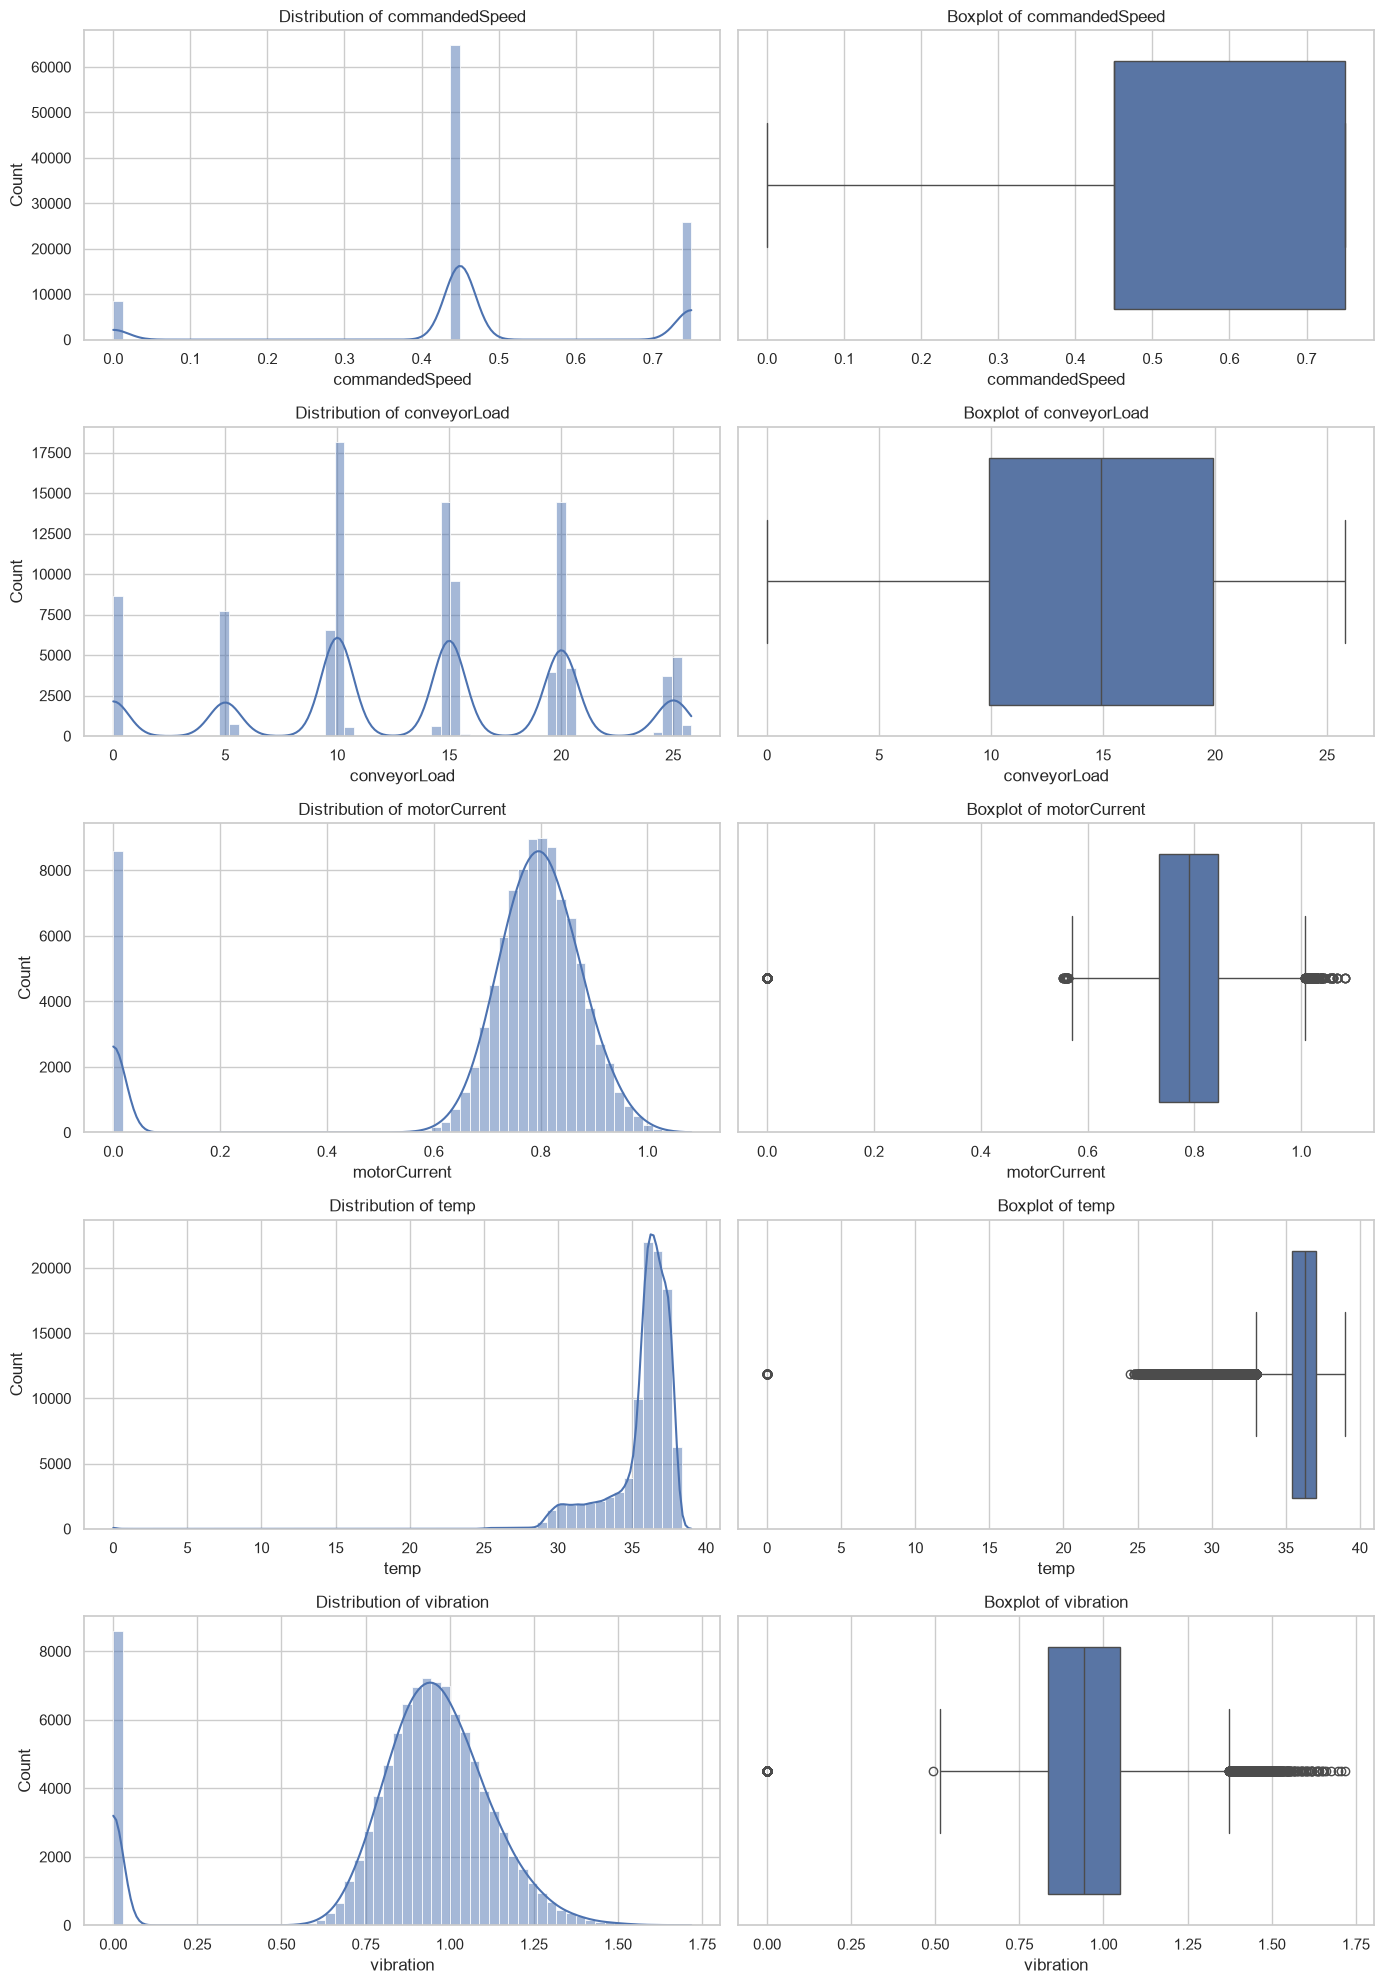

In [11]:
#DISTRIBUTIONS

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=df_viz, x=col, bins=60,
        kde=True, ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"Distribution of {col}")

    sns.boxplot(data=df_viz, x=col, ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()


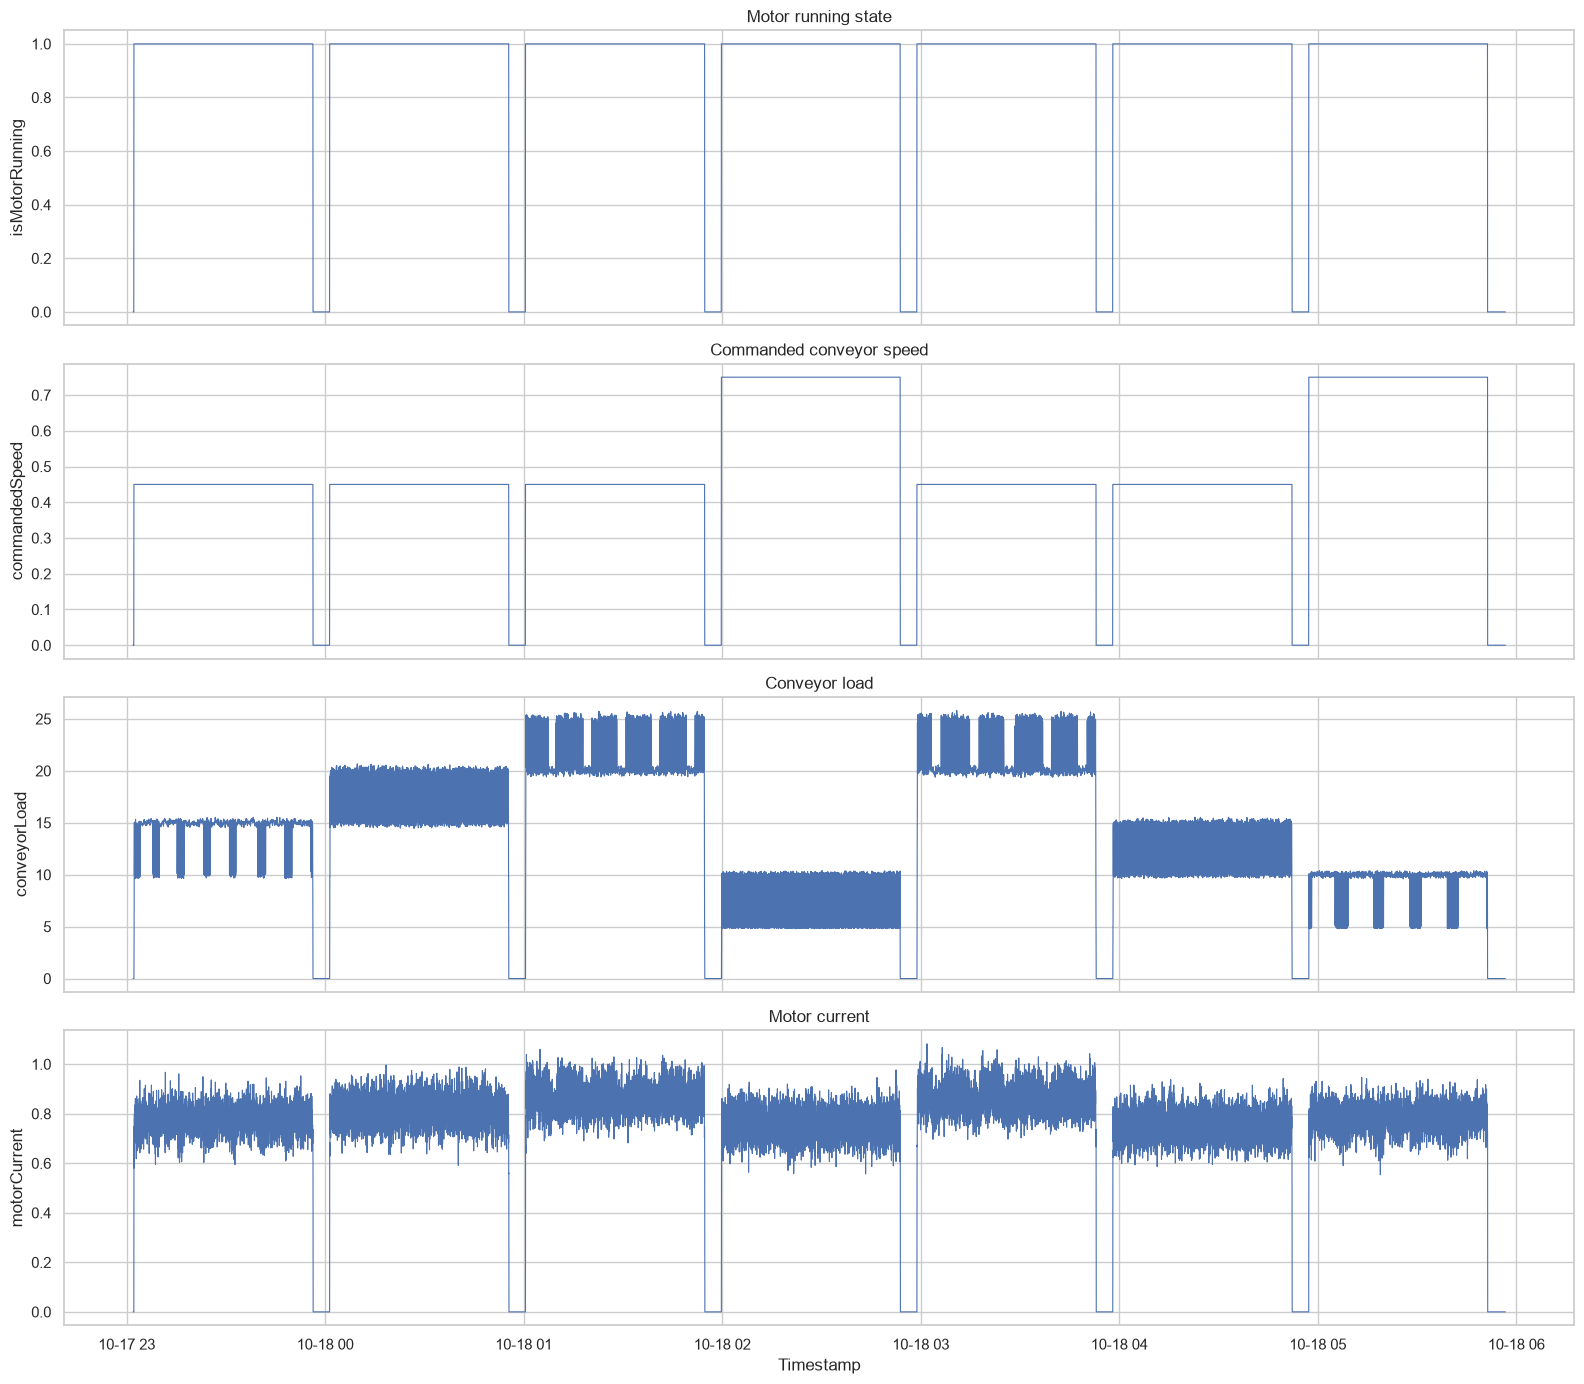

In [12]:
#MOTOR STATE AND OPERATING VALUES OVER TIME

df_time = (
    df_viz[
        ["timestamp", "isMotorRunning", "commandedSpeed",
         "conveyorLoad", "motorCurrent"]
    ]
    .drop_duplicates(subset="timestamp")
    .sort_values("timestamp")
    .copy()
)

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)

time_plots = [
    ("isMotorRunning", "Motor running state"),
    ("commandedSpeed", "Commanded conveyor speed"),
    ("conveyorLoad", "Conveyor load"),
    ("motorCurrent", "Motor current")
]

for ax, (col, title) in zip(axes, time_plots):
    ax.plot(df_time["timestamp"], df_time[col], linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel(col)

axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()


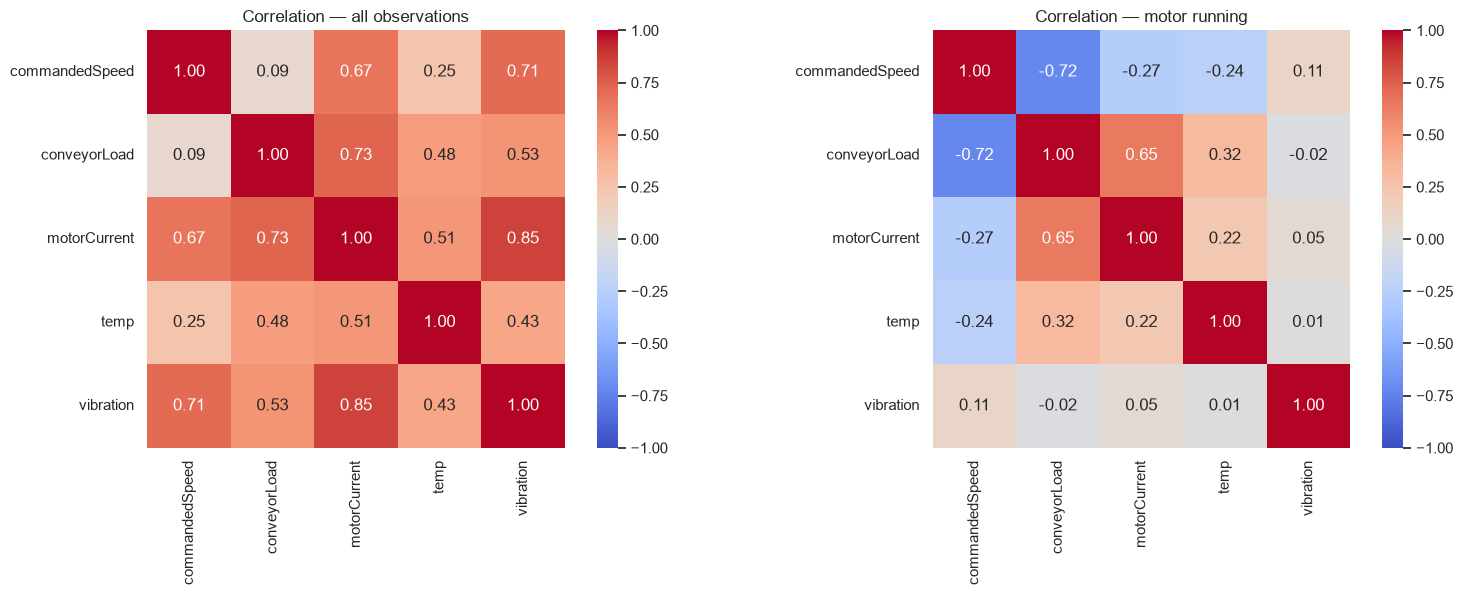

In [13]:
#CORRELATION HEATMAPS

corr_cols = [
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration"
]

df_running_viz = df_viz[df_viz["isMotorRunning"].eq(1)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_all = df_viz[corr_cols].corr()
corr_running = df_running_viz[corr_cols].corr()

sns.heatmap(
    corr_all, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, ax=axes[0]
)
axes[0].set_title("Correlation — all observations")

sns.heatmap(
    corr_running, annot=True, fmt=".2f",
    cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, ax=axes[1]
)
axes[1].set_title("Correlation — motor running")

plt.tight_layout()
plt.show()


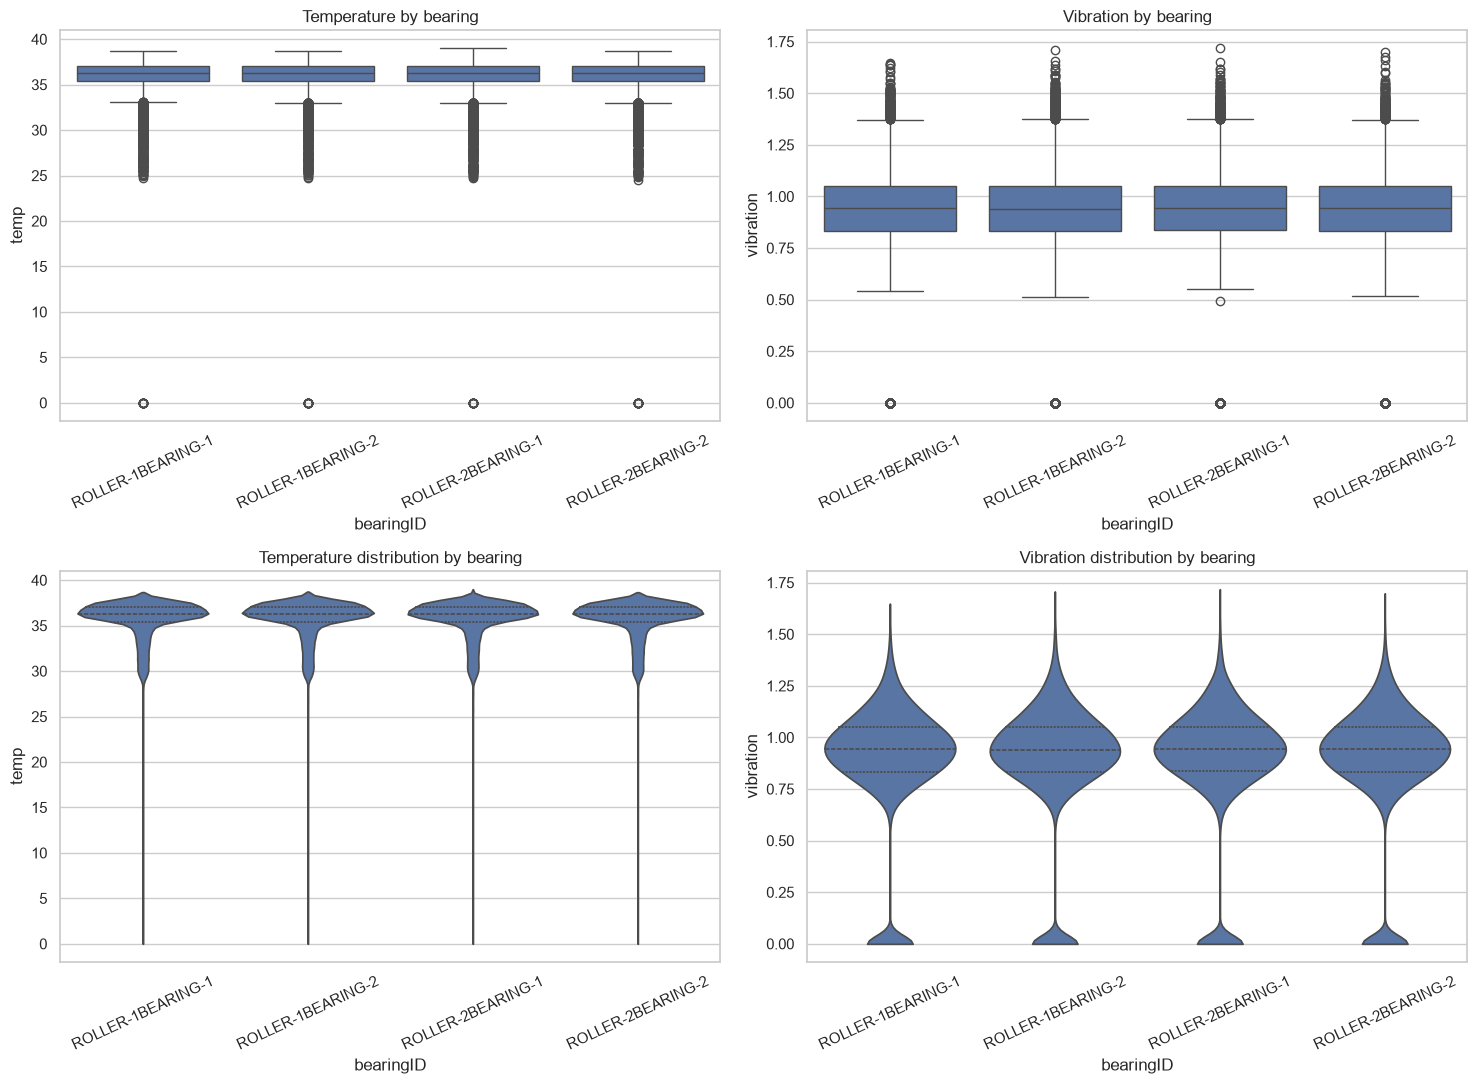

In [14]:
#BEARING WISE COMPARISIONS

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(
    data=df_viz, x="bearingID", y="temp",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Temperature by bearing")
axes[0, 0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=df_viz, x="bearingID", y="vibration",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Vibration by bearing")
axes[0, 1].tick_params(axis="x", rotation=25)

sns.violinplot(
    data=df_viz, x="bearingID", y="temp",
    inner="quartile", cut=0, ax=axes[1, 0]
)
axes[1, 0].set_title("Temperature distribution by bearing")
axes[1, 0].tick_params(axis="x", rotation=25)

sns.violinplot(
    data=df_viz, x="bearingID", y="vibration",
    inner="quartile", cut=0, ax=axes[1, 1]
)
axes[1, 1].set_title("Vibration distribution by bearing")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


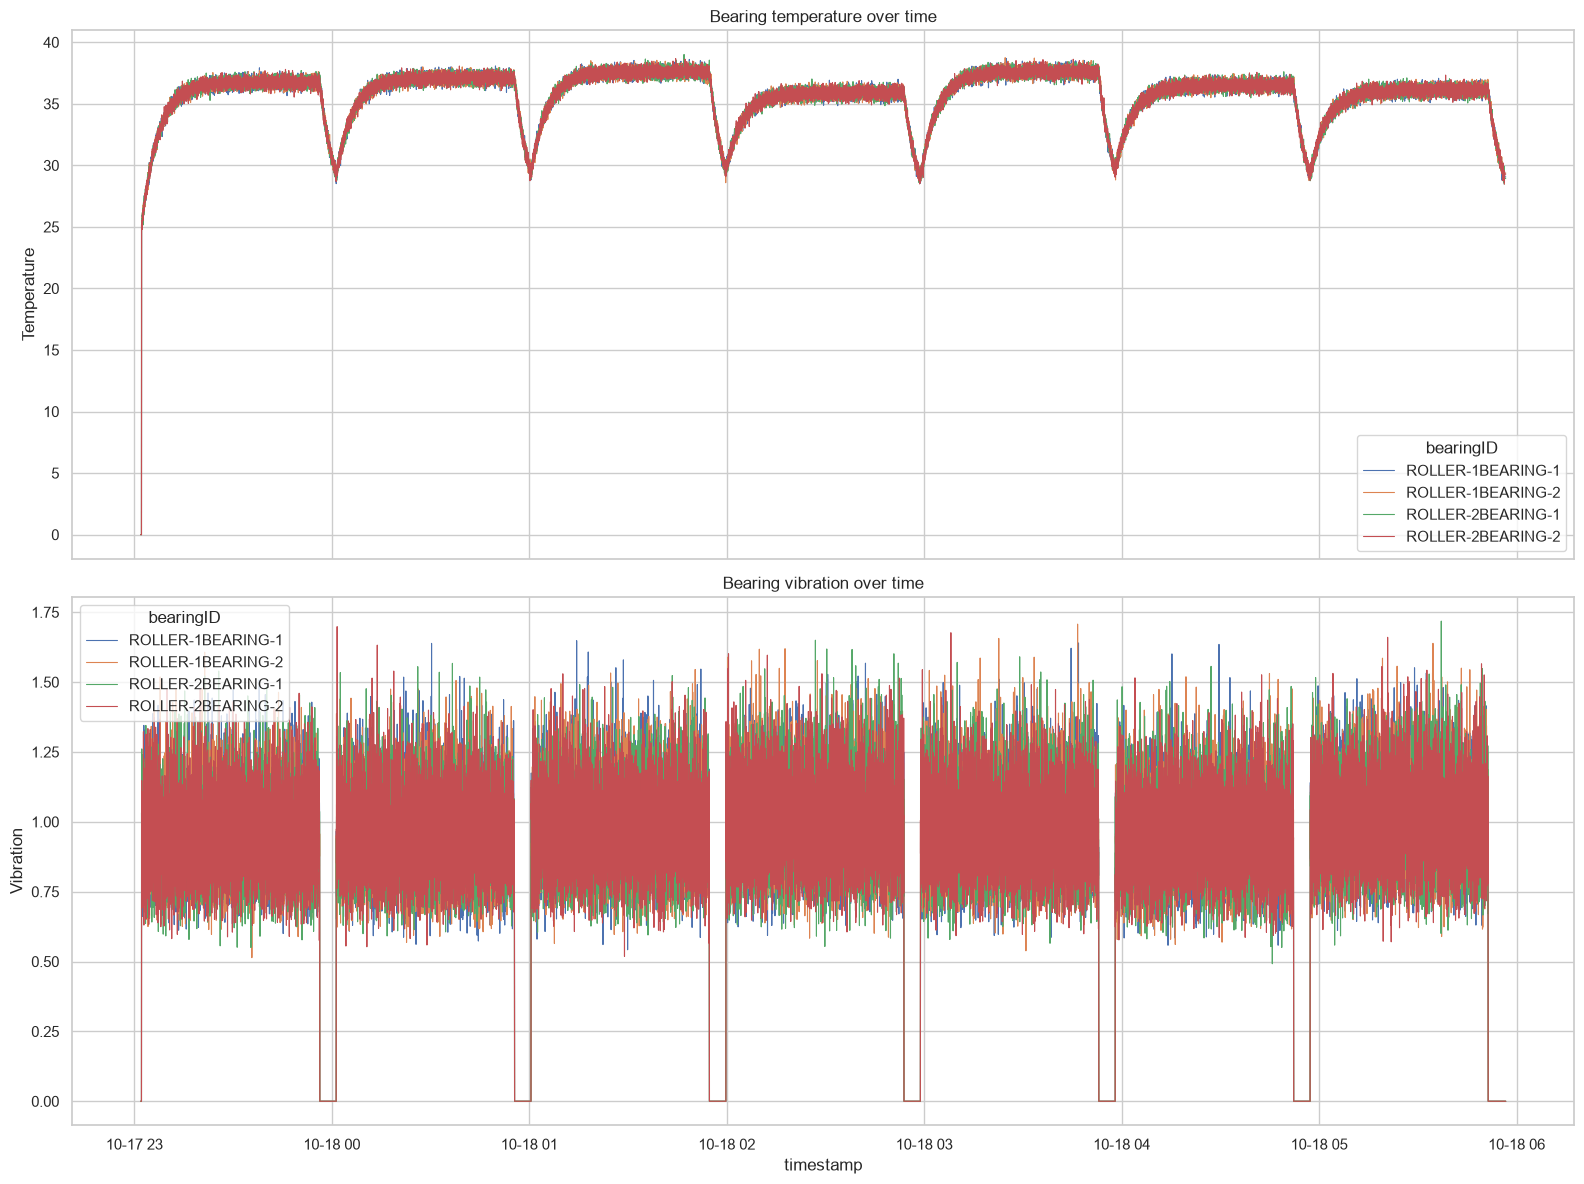

In [15]:
#TIME SERIES OF TEMPERATURE AND VIBRATION

fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)

sns.lineplot(
    data=df_viz, x="timestamp", y="temp",
    hue="bearingID", linewidth=0.8, ax=axes[0]
)
axes[0].set_title("Bearing temperature over time")
axes[0].set_ylabel("Temperature")

sns.lineplot(
    data=df_viz, x="timestamp", y="vibration",
    hue="bearingID", linewidth=0.8, ax=axes[1]
)
axes[1].set_title("Bearing vibration over time")
axes[1].set_ylabel("Vibration")

plt.tight_layout()
plt.show()


In [16]:
#NUMERICAL COMPARISON BY BEARING

bearing_summary = (
    df_viz.groupby("bearingID")
    .agg(
        temp_mean=("temp", "mean"),
        temp_std=("temp", "std"),
        temp_median=("temp", "median"),
        temp_p95=("temp", lambda s: s.quantile(0.95)),
        vibration_mean=("vibration", "mean"),
        vibration_std=("vibration", "std"),
        vibration_median=("vibration", "median"),
        vibration_p95=("vibration", lambda s: s.quantile(0.95)),
        current_mean=("motorCurrent", "mean")
    )
)

display(bearing_summary.round(4))


,temp_mean,temp_std,temp_median,temp_p95,vibration_mean,vibration_std,vibration_median,vibration_p95,current_mean
bearingID,,,,,,,,,
ROLLER-1BEARING-1,35.7138,2.2462,36.2983,37.7736,0.8851,0.3065,0.9422,1.2175,0.7313
ROLLER-1BEARING-2,35.7156,2.2433,36.3084,37.7636,0.8856,0.3074,0.9404,1.2250,0.7313
ROLLER-2BEARING-1,35.7142,2.2476,36.3072,37.7712,0.8850,0.3067,0.9419,1.2209,0.7313
ROLLER-2BEARING-2,35.7129,2.2468,36.3062,37.7584,0.8846,0.3064,0.9416,1.2197,0.7313


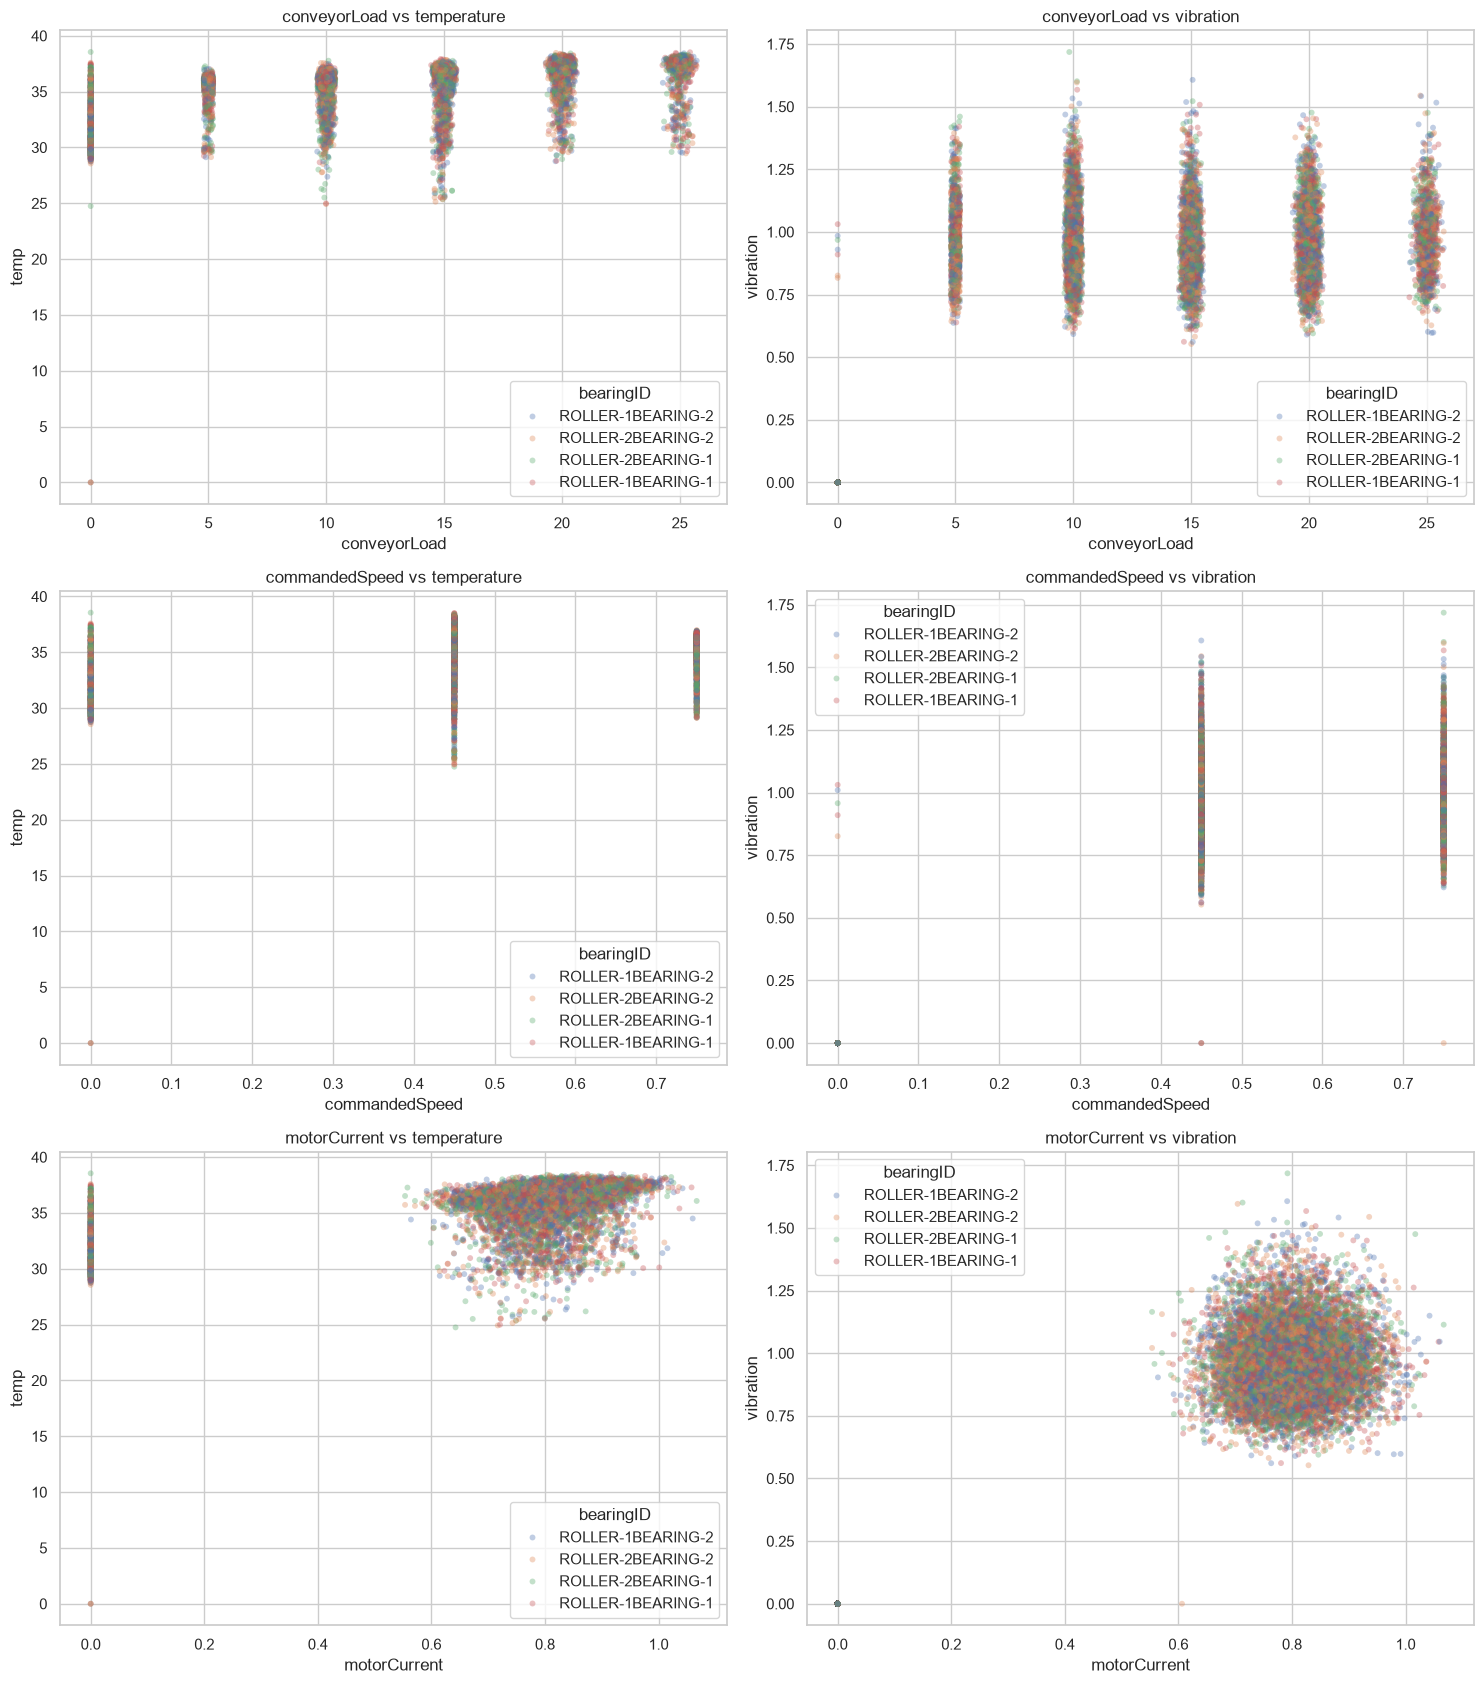

In [17]:
#Scatter plots of operating conditions against bearing measurements

plot_cols = [
    "conveyorLoad",
    "commandedSpeed",
    "motorCurrent"
]

plot_df = df_viz.sample(
    n=min(12000, len(df_viz)),
    random_state=42
)

fig, axes = plt.subplots(3, 2, figsize=(15, 17))

for i, x_col in enumerate(plot_cols):
    sns.scatterplot(
        data=plot_df, x=x_col, y="temp",
        hue="bearingID", alpha=0.35, s=18,
        linewidth=0, ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{x_col} vs temperature")

    sns.scatterplot(
        data=plot_df, x=x_col, y="vibration",
        hue="bearingID", alpha=0.35, s=18,
        linewidth=0, ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"{x_col} vs vibration")

plt.tight_layout()
plt.show()


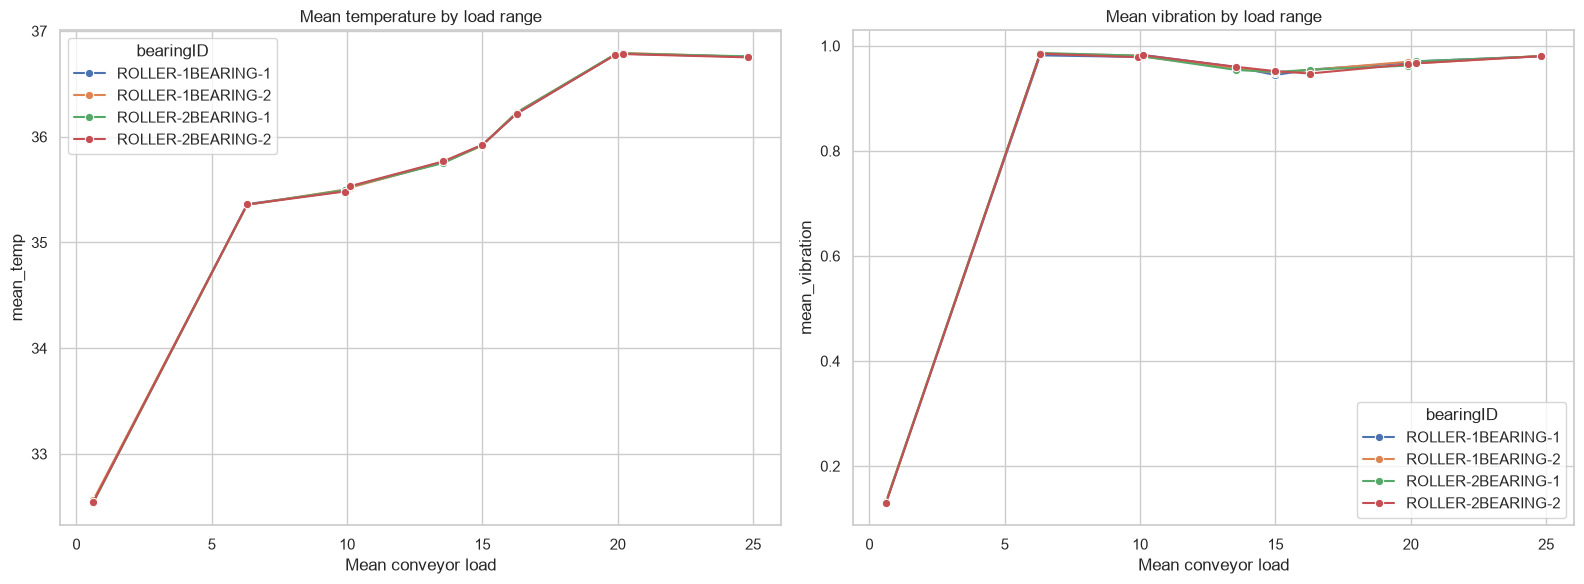

,bearingID,load_bin,mean_load,mean_temp,mean_vibration,count
0,ROLLER-1BEARING-1,"(-0.0010625, 4.863]",0.618518,32.544326,0.131491,2484
1,ROLLER-1BEARING-1,"(4.863, 9.795]",6.308088,35.363190,0.981801,2482
2,ROLLER-1BEARING-1,"(9.795, 10.004]",9.910863,35.486767,0.978888,2481
3,ROLLER-1BEARING-1,"(10.004, 10.209]",10.095278,35.526896,0.982689,2483
4,ROLLER-1BEARING-1,"(10.209, 14.893]",13.554899,35.761402,0.959459,2482
5,ROLLER-1BEARING-1,"(14.893, 15.098]",14.995905,35.921776,0.944428,2483
6,ROLLER-1BEARING-1,"(15.098, 19.71]",16.261571,36.218394,0.954584,2481
7,ROLLER-1BEARING-1,"(19.71, 20.033]",19.890390,36.775056,0.967769,2484
8,ROLLER-1BEARING-1,"(20.033, 20.479]",20.194452,36.785337,0.970507,2481
9,ROLLER-1BEARING-1,"(20.479, 25.809]",24.821105,36.757027,0.979961,2482


In [18]:
#Compare operating conditions using binned load

df_load = df_viz.copy()

df_load["load_bin"] = pd.qcut(
    df_load["conveyorLoad"],
    q=10,
    duplicates="drop"
)

load_summary = (
    df_load.groupby(["bearingID", "load_bin"], observed=True)
    .agg(
        mean_load=("conveyorLoad", "mean"),
        mean_temp=("temp", "mean"),
        mean_vibration=("vibration", "mean"),
        count=("temp", "size")
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=load_summary, x="mean_load", y="mean_temp",
    hue="bearingID", marker="o", ax=axes[0]
)
axes[0].set_title("Mean temperature by load range")
axes[0].set_xlabel("Mean conveyor load")

sns.lineplot(
    data=load_summary, x="mean_load", y="mean_vibration",
    hue="bearingID", marker="o", ax=axes[1]
)
axes[1].set_title("Mean vibration by load range")
axes[1].set_xlabel("Mean conveyor load")

plt.tight_layout()
plt.show()

display(load_summary.head(20))


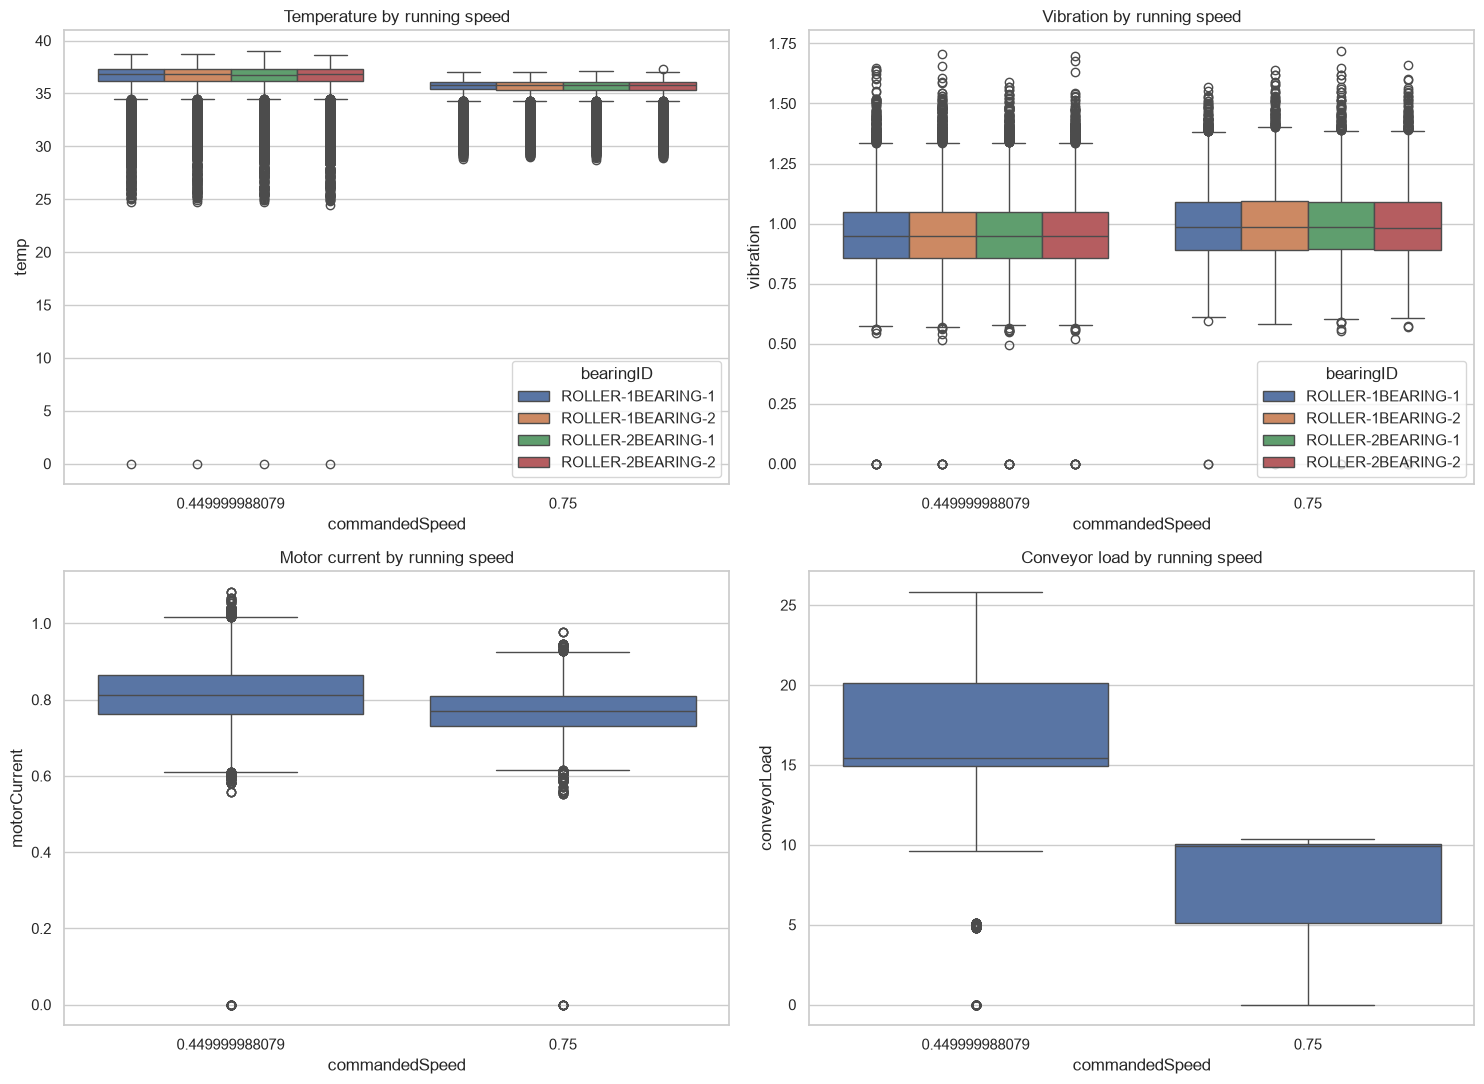

In [19]:
#COMPARE SPEED SETTINGS

df_speed = df_viz[df_viz["isMotorRunning"].eq(1)].copy()

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(
    data=df_speed, x="commandedSpeed", y="temp",
    hue="bearingID", ax=axes[0, 0]
)
axes[0, 0].set_title("Temperature by running speed")

sns.boxplot(
    data=df_speed, x="commandedSpeed", y="vibration",
    hue="bearingID", ax=axes[0, 1]
)
axes[0, 1].set_title("Vibration by running speed")

sns.boxplot(
    data=df_speed, x="commandedSpeed", y="motorCurrent",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Motor current by running speed")

sns.boxplot(
    data=df_speed, x="commandedSpeed", y="conveyorLoad",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Conveyor load by running speed")

plt.tight_layout()
plt.show()


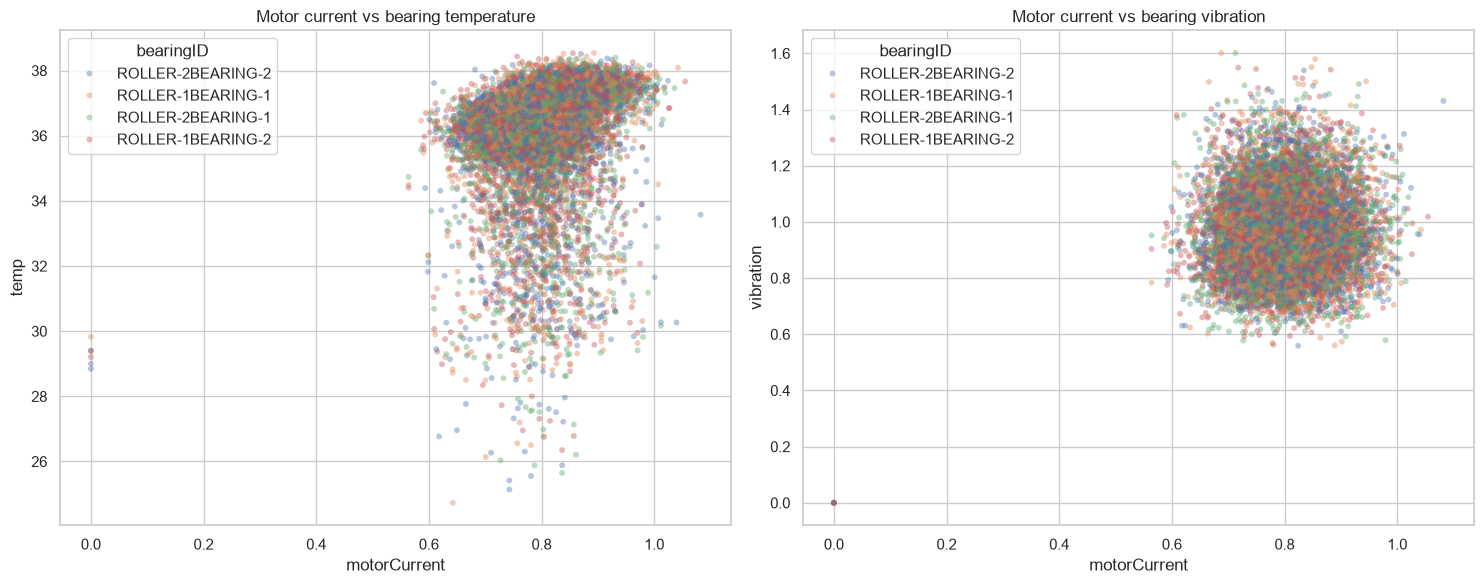

In [20]:
#MOTOR CURRENT VS TEMPERATURE AND VIBRATION

df_current = df_viz[df_viz["isMotorRunning"].eq(1)].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=df_current.sample(
        n=min(12000, len(df_current)),
        random_state=42
    ),
    x="motorCurrent", y="temp",
    hue="bearingID", alpha=0.4,
    s=18, linewidth=0, ax=axes[0]
)
axes[0].set_title("Motor current vs bearing temperature")

sns.scatterplot(
    data=df_current.sample(
        n=min(12000, len(df_current)),
        random_state=42
    ),
    x="motorCurrent", y="vibration",
    hue="bearingID", alpha=0.4,
    s=18, linewidth=0, ax=axes[1]
)
axes[1].set_title("Motor current vs bearing vibration")

plt.tight_layout()
plt.show()


In [21]:
import pandas as pd
import numpy as np

# One row per timestamp for shared conveyor signals
df_period = (
    df_bearing[
        ["timestamp", "isMotorRunning",
         "commandedSpeed", "conveyorLoad", "motorCurrent"]
    ]
    .drop_duplicates(subset="timestamp")
    .sort_values("timestamp")
    .copy()
)

# Identify state transitions
df_period["state_change"] = (
    df_period["isMotorRunning"]
    .ne(df_period["isMotorRunning"].shift())
)

# Create a new period whenever running state changes
df_period["period_id"] = df_period["state_change"].cumsum()

# Summarise each continuous period
period_summary = (
    df_period.groupby(["period_id", "isMotorRunning"])
    .agg(
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        samples=("timestamp", "size"),
        mean_speed=("commandedSpeed", "mean"),
        mean_load=("conveyorLoad", "mean"),
        mean_current=("motorCurrent", "mean"),
    )
    .reset_index()
)

period_summary["duration_minutes"] = (
    period_summary["end_time"] - period_summary["start_time"]
).dt.total_seconds() / 60

period_summary

,period_id,isMotorRunning,start_time,end_time,samples,mean_speed,mean_load,mean_current,duration_minutes
0,1,0.0,2026-10-17 23:01:54.524,2026-10-17 23:02:08.533,15,0.000000,0.000000,0.000000,0.233483
1,2,1.0,2026-10-17 23:02:09.535,2026-10-17 23:56:16.647,3232,0.450000,14.498646,0.776347,54.118533
2,3,0.0,2026-10-17 23:56:17.647,2026-10-18 00:01:18.882,302,0.000000,0.000002,0.004098,5.020583
3,4,1.0,2026-10-18 00:01:19.883,2026-10-18 00:55:27.455,3240,0.450000,17.403559,0.811638,54.126200
4,5,0.0,2026-10-18 00:55:28.456,2026-10-18 01:00:29.682,302,0.000000,0.016063,0.003704,5.020433
5,6,1.0,2026-10-18 01:00:30.682,2026-10-18 01:54:39.883,3241,0.450000,21.837802,0.863416,54.153350
6,7,0.0,2026-10-18 01:54:40.883,2026-10-18 01:59:42.109,302,0.000000,0.016628,0.004134,5.020433
7,8,1.0,2026-10-18 01:59:43.109,2026-10-18 02:53:46.129,3236,0.750000,7.413936,0.757515,54.050333
8,9,0.0,2026-10-18 02:53:47.130,2026-10-18 02:58:48.346,302,0.000000,0.017164,0.004925,5.020267
9,10,1.0,2026-10-18 02:58:49.347,2026-10-18 03:52:58.041,3242,0.450000,21.749233,0.862342,54.144900


In [22]:
# Match the period ID to every bearing observation
df_period_lookup = df_period[
    ["timestamp", "period_id", "isMotorRunning"]
].drop_duplicates(subset="timestamp")

df_bearing_periods = df_bearing.merge(
    df_period_lookup,
    on=["timestamp", "isMotorRunning"],
    how="left",
    validate="many_to_one"
)

running_bearing_summary = (
    df_bearing_periods[
        df_bearing_periods["isMotorRunning"].eq(1)
    ]
    .groupby(["period_id", "bearingID"])
    .agg(
        mean_temp=("temp", "mean"),
        std_temp=("temp", "std"),
        p95_temp=("temp", lambda s: s.quantile(0.95)),
        mean_vibration=("vibration", "mean"),
        std_vibration=("vibration", "std"),
        p95_vibration=("vibration", lambda s: s.quantile(0.95)),
        samples=("timestamp", "size"),
    )
    .reset_index()
)

running_bearing_summary

,period_id,bearingID,mean_temp,std_temp,p95_temp,mean_vibration,std_vibration,p95_vibration,samples
0,2,ROLLER-1BEARING-1,35.640171,2.392361,37.154955,0.943147,0.143450,1.203123,3232
1,2,ROLLER-1BEARING-2,35.637577,2.392684,37.135666,0.947652,0.142428,1.194471,3232
2,2,ROLLER-2BEARING-1,35.642920,2.394816,37.159015,0.948036,0.142110,1.195650,3232
3,2,ROLLER-2BEARING-2,35.640841,2.399172,37.143274,0.943120,0.145058,1.198873,3232
4,4,ROLLER-1BEARING-1,36.365572,1.564102,37.481396,0.954224,0.144453,1.202395,3240
5,4,ROLLER-1BEARING-2,36.373200,1.559061,37.504452,0.956406,0.145007,1.208948,3240
6,4,ROLLER-2BEARING-1,36.365134,1.560169,37.501837,0.957788,0.144083,1.209052,3240
7,4,ROLLER-2BEARING-2,36.372083,1.558582,37.505899,0.956392,0.144833,1.208844,3240
8,6,ROLLER-1BEARING-1,36.856229,1.629942,38.027309,0.973805,0.143970,1.223339,3241
9,6,ROLLER-1BEARING-2,36.852396,1.625947,38.005482,0.973456,0.147829,1.231407,3241


In [23]:
# Work only on a separate analysis copy
df_transient = df_bearing_periods.copy()

df_transient = df_transient[
    df_transient["isMotorRunning"].eq(1)
].copy()

# Elapsed time from the beginning of each running period
df_transient["elapsed_seconds"] = (
    df_transient["timestamp"]
    - df_transient.groupby("period_id")["timestamp"].transform("min")
).dt.total_seconds()

# Compare first 5 minutes with the remainder of each running period
df_transient["phase"] = np.where(
    df_transient["elapsed_seconds"] < 300,
    "First 5 minutes",
    "After first 5 minutes"
)

transient_summary = (
    df_transient
    .groupby(["period_id", "phase"])
    .agg(
        mean_temp=("temp", "mean"),
        std_temp=("temp", "std"),
        mean_vibration=("vibration", "mean"),
        std_vibration=("vibration", "std"),
        mean_current=("motorCurrent", "mean"),
        samples=("timestamp", "size")
    )
    .reset_index()
)

transient_summary

,period_id,phase,mean_temp,std_temp,mean_vibration,std_vibration,mean_current,samples
0,2,After first 5 minutes,36.297686,0.933296,0.945471,0.142497,0.776858,11736
1,2,First 5 minutes,29.168754,2.733945,0.945667,0.150725,0.771319,1192
2,4,After first 5 minutes,36.803458,0.655191,0.956746,0.143232,0.812849,11760
3,4,First 5 minutes,32.111278,1.452007,0.950879,0.157178,0.799775,1200
4,6,After first 5 minutes,37.309456,0.680701,0.972309,0.144494,0.863189,11764
5,6,First 5 minutes,32.413345,1.536374,0.968206,0.153315,0.865637,1200
6,8,After first 5 minutes,35.655617,0.550977,0.993309,0.150753,0.758058,11744
7,8,First 5 minutes,31.905436,1.178438,0.988565,0.165068,0.752197,1200
8,10,After first 5 minutes,37.291792,0.713270,0.974149,0.147227,0.862484,11768
9,10,First 5 minutes,32.132824,1.611209,0.960137,0.169124,0.860949,1200


In [25]:
# Create a separate copy; leave the original datasets unchanged
df_steady = df_bearing_periods[
    df_bearing_periods["isMotorRunning"].eq(1)
].copy()

# Calculate elapsed time from the start of each running period
df_steady["elapsed_seconds"] = (
    df_steady["timestamp"]
    - df_steady.groupby("period_id")["timestamp"].transform("min")
).dt.total_seconds()

# Exclude the first 5 minutes of each running period
df_steady = df_steady[
    df_steady["elapsed_seconds"] >= 300
].copy()

df_steady = df_steady.sort_values(
    ["bearingID", "timestamp"]
).reset_index(drop=True)

print("Dataset shape:", df_steady.shape)

print("\nRows per period:")
print(df_steady.groupby("period_id").size())

print("\nRows per bearing:")
print(df_steady.groupby("bearingID").size())

print("\nMissing values:")
print(
    df_steady[
        ["temp", "vibration", "motorCurrent",
         "conveyorLoad", "commandedSpeed"]
    ].isna().sum()
)

Dataset shape: (82300, 12)

Rows per period:
period_id
2     11736
4     11760
6     11764
8     11744
10    11768
12    11784
14    11744
dtype: int64

Rows per bearing:
bearingID
ROLLER-1BEARING-1    20575
ROLLER-1BEARING-2    20575
ROLLER-2BEARING-1    20575
ROLLER-2BEARING-2    20575
dtype: int64

Missing values:
temp              0
vibration         0
motorCurrent      0
conveyorLoad      0
commandedSpeed    0
dtype: int64


In [26]:
# Work on a copy; preserve df_bearing_periods unchanged.
df_steady = df_bearing_periods.copy()

# Calculate elapsed seconds from the start of each running period.
df_steady["elapsed_seconds"] = (
    df_steady["timestamp"]
    - df_steady.groupby("period_id")["timestamp"].transform("min")
).dt.total_seconds()

# Keep only samples from 5 minutes after each period begins.
df_steady = df_steady[
    (df_steady["isMotorRunning"] == 1)
    & (df_steady["elapsed_seconds"] >= 300)
].copy()

df_steady = df_steady.sort_values(
    ["bearingID", "timestamp"]
).reset_index(drop=True)

print("Steady-running dataset shape:", df_steady.shape)
print("\nRows per period:")
print(df_steady.groupby("period_id").size())

print("\nRows per bearing:")
print(df_steady["bearingID"].value_counts().sort_index())

print("\nElapsed-time range:")
print(df_steady["elapsed_seconds"].agg(["min", "max"]))

Steady-running dataset shape: (82300, 12)

Rows per period:
period_id
2     11736
4     11760
6     11764
8     11744
10    11768
12    11784
14    11744
dtype: int64

Rows per bearing:
bearingID
ROLLER-1BEARING-1    20575
ROLLER-1BEARING-2    20575
ROLLER-2BEARING-1    20575
ROLLER-2BEARING-2    20575
Name: count, dtype: int64

Elapsed-time range:
min     300.232
max    3250.560
Name: elapsed_seconds, dtype: float64


In [27]:
print(df_steady.columns.tolist())
print(df_steady.dtypes)
print(df_steady.head())

['bearingID', 'timestamp', 'isMotorRunning', 'commandedSpeed', 'conveyorLoad', 'motorCurrent', 'temp', 'vibration', 'temp_source_timestamp', 'vibration_source_timestamp', 'period_id', 'elapsed_seconds']
bearingID                                str
timestamp                     datetime64[us]
isMotorRunning                       float64
commandedSpeed                       float64
conveyorLoad                         float64
motorCurrent                         float64
temp                                 float64
vibration                            float64
temp_source_timestamp         datetime64[us]
vibration_source_timestamp    datetime64[us]
period_id                              int64
elapsed_seconds                      float64
dtype: object
           bearingID               timestamp  isMotorRunning  commandedSpeed  \
0  ROLLER-1BEARING-1 2026-10-17 23:07:09.767             1.0            0.45   
1  ROLLER-1BEARING-1 2026-10-17 23:07:10.767             1.0            0.45   
2  

In [28]:
df_steady = df_steady.sort_values(
    ["bearingID", "period_id", "timestamp"]
).copy()

df_steady["time_diff_seconds"] = (
    df_steady
    .groupby(["bearingID", "period_id"])["timestamp"]
    .diff()
    .dt.total_seconds()
)

print(df_steady["time_diff_seconds"].describe())
print("Intervals over 1.5 seconds:",
      (df_steady["time_diff_seconds"] > 1.5).sum())
print("Non-positive intervals:",
      (df_steady["time_diff_seconds"] <= 0).sum())

count    82272.000000
mean         1.002747
std          0.051623
min          1.000000
25%          1.000000
50%          1.001000
75%          1.001000
max          7.205000
Name: time_diff_seconds, dtype: float64
Intervals over 1.5 seconds: 68
Non-positive intervals: 0


In [29]:

# Sort chronologically within each bearing and operating period
df_steady = df_steady.sort_values(
    ["bearingID", "period_id", "timestamp"]
).copy()

# Calculate the interval between consecutive readings
df_steady["time_diff_seconds"] = (
    df_steady
    .groupby(["bearingID", "period_id"])["timestamp"]
    .diff()
    .dt.total_seconds()
)

# Overall interval statistics
print("Interval statistics:")
print(df_steady["time_diff_seconds"].describe())

# Count unexpected intervals
print(
    "\nIntervals greater than 1.5 seconds:",
    (df_steady["time_diff_seconds"] > 1.5).sum()
)

print(
    "Non-positive intervals:",
    (df_steady["time_diff_seconds"] <= 0).sum()
)

# Inspect intervals outside the expected range
irregular_intervals = df_steady[
    (df_steady["time_diff_seconds"] > 1.5)
    | (df_steady["time_diff_seconds"] <= 0)
]

print("\nIrregular interval examples:")
print(
    irregular_intervals[
        ["bearingID", "period_id", "timestamp", "time_diff_seconds"]
    ].head(20)
)


Interval statistics:
count    82272.000000
mean         1.002747
std          0.051623
min          1.000000
25%          1.000000
50%          1.001000
75%          1.001000
max          7.205000
Name: time_diff_seconds, dtype: float64

Intervals greater than 1.5 seconds: 68
Non-positive intervals: 0

Irregular interval examples:
               bearingID  period_id               timestamp  time_diff_seconds
521    ROLLER-1BEARING-1          2 2026-10-17 23:15:52.534              2.000
1072   ROLLER-1BEARING-1          2 2026-10-17 23:25:10.174              7.205
1073   ROLLER-1BEARING-1          2 2026-10-17 23:25:12.236              2.062
1421   ROLLER-1BEARING-1          2 2026-10-17 23:31:01.507              2.000
3332   ROLLER-1BEARING-1          4 2026-10-18 00:13:00.362              2.001
3716   ROLLER-1BEARING-1          4 2026-10-18 00:19:26.127              2.001
4457   ROLLER-1BEARING-1          4 2026-10-18 00:31:49.262              2.000
6621   ROLLER-1BEARING-1          6

In [30]:
# Show all intervals longer than 1.5 seconds
large_gaps = (
    df_steady[df_steady["time_diff_seconds"] > 1.5]
    [
        [
            "bearingID",
            "period_id",
            "timestamp",
            "time_diff_seconds",
            "elapsed_seconds",
        ]
    ]
    .sort_values("time_diff_seconds", ascending=False)
)

print("Number of large gaps:", len(large_gaps))
display(large_gaps)

Number of large gaps: 68


,bearingID,period_id,timestamp,time_diff_seconds,elapsed_seconds
1072,ROLLER-1BEARING-1,2,2026-10-17 23:25:10.174,7.205,1380.639
62797,ROLLER-2BEARING-2,2,2026-10-17 23:25:10.174,7.205,1380.639
42222,ROLLER-2BEARING-1,2,2026-10-17 23:25:10.174,7.205,1380.639
21647,ROLLER-1BEARING-2,2,2026-10-17 23:25:10.174,7.205,1380.639
42223,ROLLER-2BEARING-1,2,2026-10-17 23:25:12.236,2.062,1382.701
...,...,...,...,...,...
63146,ROLLER-2BEARING-2,2,2026-10-17 23:31:01.507,2.000,1731.972
68346,ROLLER-2BEARING-2,6,2026-10-18 01:18:01.012,2.000,1050.330
66182,ROLLER-2BEARING-2,4,2026-10-18 00:31:49.262,2.000,1829.379
77260,ROLLER-2BEARING-2,12,2026-10-18 04:17:06.213,2.000,1144.953


In [31]:
gap_summary = (
    large_gaps.groupby(["period_id", "timestamp"])
    .agg(
        affected_bearings=("bearingID", "nunique"),
        max_gap_seconds=("time_diff_seconds", "max"),
    )
    .sort_values("max_gap_seconds", ascending=False)
)

display(gap_summary.head(30))

affected_bearings  max_gap_seconds
period_id timestamp                                                  
2         2026-10-17 23:25:10.174                  4            7.205
          2026-10-17 23:25:12.236                  4            2.062
8         2026-10-18 02:44:22.371                  4            2.013
10        2026-10-18 03:46:03.203                  4            2.009
8         2026-10-18 02:36:42.083                  4            2.009
10        2026-10-18 03:51:11.962                  4            2.001
6         2026-10-18 01:32:32.280                  4            2.001
4         2026-10-18 00:13:00.362                  4            2.001
          2026-10-18 00:19:26.127                  4            2.001
8         2026-10-18 02:07:14.935                  4            2.001
14        2026-10-18 05:21:15.051                  4            2.001
2         2026-10-17 23:15:52.534                  4            2.000
          2026-10-17 23:31:01.507                  4            2.000
6         2026-10-18 01:18:01.012                  4            2.000
4         2026-10-18 00:31:49.262                  4            2.000
12        2026-10-18 04:17:06.213                  4            2.000
14        2026-10-18 05:36:04.989                  4            2.000

In [32]:

# Work on a copy; retain df_steady unchanged
df_model = df_steady.copy()

df_model = df_model.sort_values(
    ["bearingID", "period_id", "timestamp"]
).reset_index(drop=True)

# Recalculate intervals to ensure the values match the sorted rows
df_model["time_diff_seconds"] = (
    df_model
    .groupby(["bearingID", "period_id"])["timestamp"]
    .diff()
    .dt.total_seconds()
)

# Begin a new segment at the first row of each bearing-period
# or whenever the sampling interval exceeds 1.5 seconds
df_model["new_segment"] = (
    df_model["time_diff_seconds"].isna()
    | (df_model["time_diff_seconds"] > 1.5)
)

# Assign unique segments within each bearing-period
df_model["segment_id"] = (
    df_model.groupby(["bearingID", "period_id"])["new_segment"]
    .cumsum()
    .astype(int)
)

# Inspect the segments
segment_summary = (
    df_model.groupby(
        ["bearingID", "period_id", "segment_id"]
    )
    .agg(
        rows=("timestamp", "size"),
        start_time=("timestamp", "min"),
        end_time=("timestamp", "max"),
        max_interval=("time_diff_seconds", "max"),
    )
    .reset_index()
)

print("Total segments:", len(segment_summary))
print("Shortest segment:", segment_summary["rows"].min())
print("Longest segment:", segment_summary["rows"].max())
print("\nSegments with fewer than 30 rows:")
display(segment_summary[segment_summary["rows"] < 30])

print("\nSegment length distribution:")
print(segment_summary["rows"].describe())


Total segments: 96
Shortest segment: 1
Longest segment: 2528

Segments with fewer than 30 rows:


,bearingID,period_id,segment_id,rows,start_time,end_time,max_interval
2,ROLLER-1BEARING-1,2,3,1,2026-10-17 23:25:10.174,2026-10-17 23:25:10.174,7.205
26,ROLLER-1BEARING-2,2,3,1,2026-10-17 23:25:10.174,2026-10-17 23:25:10.174,7.205
50,ROLLER-2BEARING-1,2,3,1,2026-10-17 23:25:10.174,2026-10-17 23:25:10.174,7.205
74,ROLLER-2BEARING-2,2,3,1,2026-10-17 23:25:10.174,2026-10-17 23:25:10.174,7.205



Segment length distribution:
count      96.000000
mean      857.291667
std       631.945333
min         1.000000
25%       394.500000
50%       744.000000
75%      1184.250000
max      2528.000000
Name: rows, dtype: float64


In [33]:

WINDOW_SIZE = 30

segment_summary["possible_windows"] = (
    segment_summary["rows"] - WINDOW_SIZE + 1
).clip(lower=0)

print("Total segments:", len(segment_summary))
print(
    "Segments eligible for window generation:",
    (segment_summary["rows"] >= WINDOW_SIZE).sum()
)
print(
    "Segments too short:",
    (segment_summary["rows"] < WINDOW_SIZE).sum()
)
print(
    "Total possible windows with stride 1:",
    int(segment_summary["possible_windows"].sum())
)

print("\nWindows by bearing:")
print(
    segment_summary.groupby("bearingID")["possible_windows"]
    .sum()
)

print("\nWindows by operating period:")
print(
    segment_summary.groupby("period_id")["possible_windows"]
    .sum()
)


Total segments: 96
Segments eligible for window generation: 92
Segments too short: 4
Total possible windows with stride 1: 79628

Windows by bearing:
bearingID
ROLLER-1BEARING-1    19907
ROLLER-1BEARING-2    19907
ROLLER-2BEARING-1    19907
ROLLER-2BEARING-2    19907
Name: possible_windows, dtype: int64

Windows by operating period:
period_id
2     11268
4     11296
6     11416
8     11280
10    11420
12    11552
14    11396
Name: possible_windows, dtype: int64


In [34]:

period_conditions = (
    df_model.groupby("period_id")
    .agg(
        rows=("timestamp", "size"),
        speed_mean=("commandedSpeed", "mean"),
        speed_min=("commandedSpeed", "min"),
        speed_max=("commandedSpeed", "max"),
        load_mean=("conveyorLoad", "mean"),
        load_std=("conveyorLoad", "std"),
        current_mean=("motorCurrent", "mean"),
        temp_mean=("temp", "mean"),
        vibration_mean=("vibration", "mean"),
    )
    .round(3)
)

display(period_conditions)


,rows,speed_mean,speed_min,speed_max,load_mean,load_std,current_mean,temp_mean,vibration_mean
period_id,,,,,,,,,
2,11736,0.45,0.45,0.45,14.546,1.471,0.777,36.298,0.945
4,11760,0.45,0.45,0.45,17.443,2.528,0.813,36.803,0.957
6,11764,0.45,0.45,0.45,21.815,2.464,0.863,37.309,0.972
8,11744,0.75,0.75,0.75,7.424,2.503,0.758,35.656,0.993
10,11768,0.45,0.45,0.45,21.740,2.439,0.862,37.292,0.974
12,11784,0.45,0.45,0.45,12.499,2.518,0.751,36.246,0.944
14,11744,0.75,0.75,0.75,9.310,1.736,0.781,35.860,0.998


In [35]:

TRAIN_PERIODS = [2, 4, 6, 8]
VAL_PERIODS = [10]
TEST_PERIODS = [12, 14]

assert set(TRAIN_PERIODS).isdisjoint(VAL_PERIODS)
assert set(TRAIN_PERIODS).isdisjoint(TEST_PERIODS)
assert set(VAL_PERIODS).isdisjoint(TEST_PERIODS)

df_train = df_model[df_model["period_id"].isin(TRAIN_PERIODS)].copy()
df_val = df_model[df_model["period_id"].isin(VAL_PERIODS)].copy()
df_test = df_model[df_model["period_id"].isin(TEST_PERIODS)].copy()

print("Training rows:", len(df_train))
print("Validation rows:", len(df_val))
print("Test rows:", len(df_test))

print("\nTraining periods:", sorted(df_train["period_id"].unique()))
print("Validation periods:", sorted(df_val["period_id"].unique()))
print("Test periods:", sorted(df_test["period_id"].unique()))


Training rows: 47004
Validation rows: 11768
Test rows: 23528

Training periods: [np.int64(2), np.int64(4), np.int64(6), np.int64(8)]
Validation periods: [np.int64(10)]
Test periods: [np.int64(12), np.int64(14)]


In [36]:
FEATURES = [
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration",
]

In [37]:

from sklearn.preprocessing import StandardScaler

FEATURES = [
    "commandedSpeed",
    "conveyorLoad",
    "motorCurrent",
    "temp",
    "vibration",
]

# Fit only on training rows
scaler = StandardScaler()
scaler.fit(df_train[FEATURES])

# Transform all partitions using the training-fitted scaler
df_train_scaled = df_train.copy()
df_val_scaled = df_val.copy()
df_test_scaled = df_test.copy()

df_train_scaled[FEATURES] = scaler.transform(df_train[FEATURES])
df_val_scaled[FEATURES] = scaler.transform(df_val[FEATURES])
df_test_scaled[FEATURES] = scaler.transform(df_test[FEATURES])

print("Training feature means after scaling:")
print(df_train_scaled[FEATURES].mean().round(3))

print("\nTraining feature standard deviations after scaling:")
print(df_train_scaled[FEATURES].std().round(3))

print("\nValidation feature means after scaling:")
print(df_val_scaled[FEATURES].mean().round(3))

print("\nTest feature means after scaling:")
print(df_test_scaled[FEATURES].mean().round(3))


Training feature means after scaling:
commandedSpeed   -0.0
conveyorLoad     -0.0
motorCurrent      0.0
temp             -0.0
vibration        -0.0
dtype: float64

Training feature standard deviations after scaling:
commandedSpeed    1.0
conveyorLoad      1.0
motorCurrent      1.0
temp              1.0
vibration         1.0
dtype: float64

Validation feature means after scaling:
commandedSpeed   -0.577
conveyorLoad      1.125
motorCurrent      0.854
temp              0.820
vibration         0.049
dtype: float64

Test feature means after scaling:
commandedSpeed    0.576
conveyorLoad     -0.771
motorCurrent     -0.527
temp             -0.491
vibration         0.027
dtype: float64


In [38]:

import numpy as np

WINDOW_SIZE = 30

def make_sequences(df, features, window_size=30):
    sequences = []
    metadata = []

    group_cols = ["bearingID", "period_id", "segment_id"]

    for (bearing_id, period_id, segment_id), group in df.groupby(
        group_cols, sort=True
    ):
        group = group.sort_values("timestamp")
        values = group[features].to_numpy(dtype=np.float32)

        # Skip segments that cannot form a complete window
        if len(values) < window_size:
            continue

        # Sliding windows, with no crossing of segment boundaries
        for start in range(len(values) - window_size + 1):
            end = start + window_size
            sequences.append(values[start:end])

            # Metadata refers to the final timestamp in each window
            metadata.append({
                "bearingID": bearing_id,
                "period_id": period_id,
                "segment_id": segment_id,
                "window_start": group["timestamp"].iloc[start],
                "window_end": group["timestamp"].iloc[end - 1],
            })

    if sequences:
        X = np.stack(sequences)
    else:
        X = np.empty((0, window_size, len(features)), dtype=np.float32)

    return X, pd.DataFrame(metadata)


X_train, meta_train = make_sequences(df_train_scaled, FEATURES, WINDOW_SIZE)
X_val, meta_val = make_sequences(df_val_scaled, FEATURES, WINDOW_SIZE)
X_test, meta_test = make_sequences(df_test_scaled, FEATURES, WINDOW_SIZE)

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

print("\nMetadata shapes:")
print("meta_train:", meta_train.shape)
print("meta_val:  ", meta_val.shape)
print("meta_test: ", meta_test.shape)

# Verify that each sequence has 30 timesteps and five features
assert X_train.shape[1:] == (WINDOW_SIZE, len(FEATURES))
assert X_val.shape[1:] == (WINDOW_SIZE, len(FEATURES))
assert X_test.shape[1:] == (WINDOW_SIZE, len(FEATURES))

# Verify the number of windows matches the metadata
assert len(X_train) == len(meta_train)
assert len(X_val) == len(meta_val)
assert len(X_test) == len(meta_test)

print("\nSequence shape checks passed.")


X_train: (45260, 30, 5)
X_val:   (11420, 30, 5)
X_test:  (22948, 30, 5)

Metadata shapes:
meta_train: (45260, 5)
meta_val:   (11420, 5)
meta_test:  (22948, 5)

Sequence shape checks passed.


In [40]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [41]:
#TRAINING A LSTM MODEL
import tensorflow as tf
from tensorflow.keras import layers, Model

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Input shape: 30 timesteps × 5 features
inputs = layers.Input(shape=(WINDOW_SIZE, len(FEATURES)))

# Encoder
x = layers.LSTM(32, return_sequences=True)(inputs)
latent = layers.LSTM(16, return_sequences=False)(x)

# Decoder
x = layers.RepeatVector(WINDOW_SIZE)(latent)
x = layers.LSTM(16, return_sequences=True)(x)
x = layers.LSTM(32, return_sequences=True)(x)

# Reconstruct the five original features
outputs = layers.TimeDistributed(
    layers.Dense(len(FEATURES))
)(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 32)         │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 5)          │           165 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,549 (64.64 KB)

 Trainable params: 16,549 (64.64 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    min_delta=0.0001,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_lstm_autoencoder.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=50,
    batch_size=128,
    shuffle=True,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/50
353/354 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.4443
Epoch 1: val_loss improved from None to 0.39170, saving model to best_lstm_autoencoder.keras

Epoch 1: finished saving model to best_lstm_autoencoder.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - loss: 0.4442 - val_loss: 0.3917
Epoch 2/50
354/354 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.3766
Epoch 2: val_loss improved from 0.39170 to 0.37457, saving model to best_lstm_autoencoder.keras

Epoch 2: finished saving model to best_lstm_autoencoder.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - loss: 0.3766 - val_loss: 0.3746
Epoch 3/50
353/354 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.3715
Epoch 3: val_loss improved from 0.37457 to 0.37078, saving model to best_lstm_autoencoder.keras

Epoch 3: finished saving model to best_lstm_autoencoder.keras
354/354 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - loss: 0.3715 - val_loss: 0.3708
Epoch 4/50
352/354 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.3682
Epoch 4: val_loss impro

In [43]:
print("Epochs completed:", len(history.history["loss"]))
print("Best validation loss:", min(history.history["val_loss"]))
print("Final training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

Epochs completed: 50
Best validation loss: 0.3140071630477905
Final training loss: 0.3165019154548645
Final validation loss: 0.3140071630477905


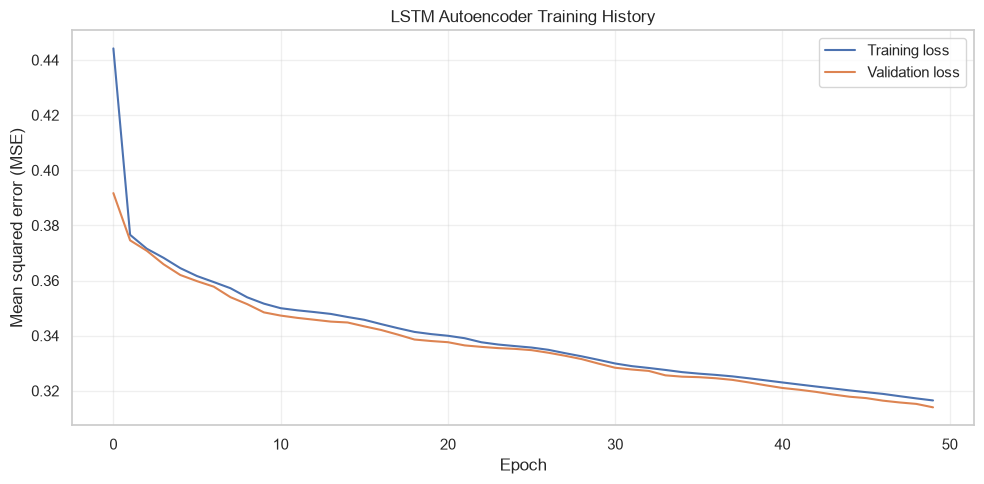

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Mean squared error (MSE)")
plt.title("LSTM Autoencoder Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
#RECONSTRUCTION ERRORS
import numpy as np
import pandas as pd

def calculate_reconstruction_errors(model, X, batch_size=128):
    X_reconstructed = model.predict(
        X,
        batch_size=batch_size,
        verbose=0
    )

    # MSE for each sequence across all timesteps and features
    errors = np.mean(
        np.square(X - X_reconstructed),
        axis=(1, 2)
    )

    return errors


train_errors = calculate_reconstruction_errors(autoencoder, X_train)
val_errors = calculate_reconstruction_errors(autoencoder, X_val)
test_errors = calculate_reconstruction_errors(autoencoder, X_test)

print("Training reconstruction errors:")
print(pd.Series(train_errors).describe())

print("\nValidation reconstruction errors:")
print(pd.Series(val_errors).describe())

print("\nTest reconstruction errors:")
print(pd.Series(test_errors).describe())

Training reconstruction errors:
count    45260.000000
mean         0.316443
std          0.067859
min          0.120007
25%          0.269811
50%          0.314257
75%          0.361014
max          0.594209
dtype: float64

Validation reconstruction errors:
count    11420.000000
mean         0.314007
std          0.064193
min          0.148758
25%          0.272058
50%          0.312630
75%          0.352286
max          0.639889
dtype: float64

Test reconstruction errors:
count    22948.000000
mean         0.321809
std          0.056682
min          0.141437
25%          0.282015
50%          0.317215
75%          0.356932
max          0.585309
dtype: float64


In [46]:
# Threshold based only on validation data
threshold_99 = np.percentile(val_errors, 99)

# Apply the fixed threshold to all datasets
train_anomaly = train_errors > threshold_99
val_anomaly = val_errors > threshold_99
test_anomaly = test_errors > threshold_99

print(f"99th-percentile validation threshold: {threshold_99:.6f}")

print(
    f"\nTraining windows flagged: {train_anomaly.sum()} / "
    f"{len(train_errors)} ({train_anomaly.mean() * 100:.2f}%)"
)

print(
    f"Validation windows flagged: {val_anomaly.sum()} / "
    f"{len(val_errors)} ({val_anomaly.mean() * 100:.2f}%)"
)

print(
    f"Test windows flagged: {test_anomaly.sum()} / "
    f"{len(test_errors)} ({test_anomaly.mean() * 100:.2f}%)"
)

99th-percentile validation threshold: 0.499913

Training windows flagged: 271 / 45260 (0.60%)
Validation windows flagged: 115 / 11420 (1.01%)
Test windows flagged: 95 / 22948 (0.41%)


In [47]:
# Attach reconstruction errors and flags to the corresponding metadata
meta_train_results = meta_train.copy()
meta_train_results["reconstruction_error"] = train_errors
meta_train_results["is_anomaly"] = train_anomaly

meta_val_results = meta_val.copy()
meta_val_results["reconstruction_error"] = val_errors
meta_val_results["is_anomaly"] = val_anomaly

meta_test_results = meta_test.copy()
meta_test_results["reconstruction_error"] = test_errors
meta_test_results["is_anomaly"] = test_anomaly

# Summarize test flags by bearing
test_bearing_summary = (
    meta_test_results.groupby("bearingID")
    .agg(
        total_windows=("is_anomaly", "size"),
        flagged_windows=("is_anomaly", "sum"),
        mean_error=("reconstruction_error", "mean"),
        max_error=("reconstruction_error", "max")
    )
)

test_bearing_summary["flagged_percent"] = (
    100 * test_bearing_summary["flagged_windows"]
    / test_bearing_summary["total_windows"]
)

print("Test anomaly summary by bearing:")
display(test_bearing_summary.round(4))

# Summarize test flags by operating period
test_period_summary = (
    meta_test_results.groupby("period_id")
    .agg(
        total_windows=("is_anomaly", "size"),
        flagged_windows=("is_anomaly", "sum"),
        mean_error=("reconstruction_error", "mean"),
        max_error=("reconstruction_error", "max")
    )
)

test_period_summary["flagged_percent"] = (
    100 * test_period_summary["flagged_windows"]
    / test_period_summary["total_windows"]
)

print("\nTest anomaly summary by period:")
display(test_period_summary.round(4))

Test anomaly summary by bearing:


,total_windows,flagged_windows,mean_error,max_error,flagged_percent
bearingID,,,,,
ROLLER-1BEARING-1,5737,26,0.3173,0.5640,0.4532
ROLLER-1BEARING-2,5737,18,0.3252,0.5641,0.3138
ROLLER-2BEARING-1,5737,33,0.3235,0.5853,0.5752
ROLLER-2BEARING-2,5737,18,0.3212,0.5537,0.3138



Test anomaly summary by period:


,total_windows,flagged_windows,mean_error,max_error,flagged_percent
period_id,,,,,
12,11552,57,0.3265,0.5853,0.4934
14,11396,38,0.3171,0.5641,0.3335


In [48]:
# Extract only flagged test windows
flagged_test = (
    meta_test_results.loc[meta_test_results["is_anomaly"]]
    .sort_values(["bearingID", "period_id", "window_start"])
    .copy()
)

# Calculate the gap between successive flagged window starts
flagged_test["gap_seconds"] = (
    flagged_test.groupby(["bearingID", "period_id"])["window_start"]
    .diff()
    .dt.total_seconds()
)

# Start a new episode if the gap exceeds 2 seconds
flagged_test["new_episode"] = (
    flagged_test["gap_seconds"].isna()
    | (flagged_test["gap_seconds"] > 2.0)
)

flagged_test["episode_number"] = (
    flagged_test.groupby(["bearingID", "period_id"])["new_episode"]
    .cumsum()
)

# Summarize each episode
episode_summary = (
    flagged_test.groupby(
        ["bearingID", "period_id", "episode_number"],
        as_index=False
    )
    .agg(
        episode_start=("window_start", "min"),
        episode_end=("window_end", "max"),
        flagged_windows=("is_anomaly", "size"),
        peak_error=("reconstruction_error", "max"),
        mean_error=("reconstruction_error", "mean")
    )
    .sort_values("peak_error", ascending=False)
)

print("Number of flagged windows:", len(flagged_test))
print("Number of grouped episodes:", len(episode_summary))

display(episode_summary.head(20).round(4))

Number of flagged windows: 95
Number of grouped episodes: 33


C:\Users\FRONTECH\AppData\Local\Temp\ipykernel_9148\1700987694.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(episode_summary.head(20).round(4))


,bearingID,period_id,episode_number,episode_start,episode_end,flagged_windows,peak_error,mean_error
20,ROLLER-2BEARING-1,12,7,2026-10-18 04:48:11.638,2026-10-18 04:48:45.662,6,0.5853,0.5423
18,ROLLER-2BEARING-1,12,5,2026-10-18 04:44:47.474,2026-10-18 04:45:20.499,5,0.5818,0.5258
11,ROLLER-1BEARING-2,14,2,2026-10-18 05:34:07.438,2026-10-18 05:34:42.461,7,0.5641,0.5236
1,ROLLER-1BEARING-1,12,2,2026-10-18 04:15:02.125,2026-10-18 04:15:35.146,5,0.5640,0.5365
12,ROLLER-1BEARING-2,14,3,2026-10-18 05:34:24.449,2026-10-18 05:34:56.474,4,0.5612,0.5381
29,ROLLER-2BEARING-2,14,2,2026-10-18 05:19:18.968,2026-10-18 05:19:53.991,7,0.5537,0.5256
30,ROLLER-2BEARING-2,14,3,2026-10-18 05:24:18.592,2026-10-18 05:24:51.612,5,0.5506,0.5293
0,ROLLER-1BEARING-1,12,1,2026-10-18 04:14:49.112,2026-10-18 04:15:29.140,12,0.5382,0.5209
31,ROLLER-2BEARING-2,14,4,2026-10-18 05:24:24.595,2026-10-18 05:24:54.617,2,0.5380,0.5210
22,ROLLER-2BEARING-1,12,9,2026-10-18 04:51:18.781,2026-10-18 04:51:50.805,4,0.5371,0.5168


In [49]:
# Inspect the 5 highest-error episodes
top_episodes = episode_summary.nlargest(5, "peak_error")

for _, episode in top_episodes.iterrows():
    bearing = episode["bearingID"]
    period = episode["period_id"]
    start = episode["episode_start"]
    end = episode["episode_end"]

    print("\n" + "=" * 80)
    print(
        f"Bearing: {bearing} | Period: {period} | "
        f"Peak error: {episode['peak_error']:.4f}"
    )
    print(f"Episode window range: {start} to {end}")

    # Include a small amount of context before and after the episode.
    context_start = start - pd.Timedelta(seconds=10)
    context_end = end + pd.Timedelta(seconds=10)

    readings = df_model[
        (df_model["bearingID"] == bearing)
        & (df_model["period_id"] == period)
        & (df_model["timestamp"] >= context_start)
        & (df_model["timestamp"] <= context_end)
    ][
        [
            "timestamp",
            "commandedSpeed",
            "conveyorLoad",
            "motorCurrent",
            "temp",
            "vibration",
        ]
    ].sort_values("timestamp")

    display(readings.round(3))


Bearing: ROLLER-2BEARING-1 | Period: 12 | Peak error: 0.5853
Episode window range: 2026-10-18 04:48:11.638000 to 2026-10-18 04:48:45.662000


C:\Users\FRONTECH\AppData\Local\Temp\ipykernel_9148\2698254916.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(readings.round(3))


,timestamp,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
58539,2026-10-18 04:48:02.630,0.45,10.182,0.658,36.829,1.115
58540,2026-10-18 04:48:03.630,0.45,15.328,0.745,36.167,0.871
58541,2026-10-18 04:48:04.631,0.45,10.328,0.827,35.933,0.936
58542,2026-10-18 04:48:05.631,0.45,10.328,0.794,36.677,0.855
58543,2026-10-18 04:48:06.632,0.45,15.372,0.779,36.539,0.759
58544,2026-10-18 04:48:07.633,0.45,15.372,0.827,36.180,0.928
58545,2026-10-18 04:48:08.635,0.45,10.189,0.618,36.330,1.059
58546,2026-10-18 04:48:09.635,0.45,10.189,0.649,36.551,0.921
58547,2026-10-18 04:48:10.637,0.45,15.360,0.835,36.814,0.816
58548,2026-10-18 04:48:11.638,0.45,10.214,0.709,36.196,1.186



Bearing: ROLLER-2BEARING-1 | Period: 12 | Peak error: 0.5818
Episode window range: 2026-10-18 04:44:47.474000 to 2026-10-18 04:45:20.499000


C:\Users\FRONTECH\AppData\Local\Temp\ipykernel_9148\2698254916.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(readings.round(3))


...

C:\Users\FRONTECH\AppData\Local\Temp\ipykernel_9148\2698254916.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(readings.round(3))


,timestamp,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
15403,2026-10-18 04:14:53.117,0.45,15.303,0.705,36.323,1.052
15404,2026-10-18 04:14:54.119,0.45,15.303,0.827,36.391,0.907
15405,2026-10-18 04:14:55.120,0.45,10.320,0.727,36.051,0.901
15406,2026-10-18 04:14:56.121,0.45,15.501,0.727,36.793,0.953
15407,2026-10-18 04:14:57.122,0.45,15.501,0.824,36.365,0.852
15408,2026-10-18 04:14:58.122,0.45,10.375,0.711,36.139,0.921
15409,2026-10-18 04:14:59.123,0.45,10.375,0.697,35.916,0.951
15410,2026-10-18 04:15:00.124,0.45,15.428,0.876,36.308,1.276
15411,2026-10-18 04:15:01.125,0.45,15.428,0.724,36.278,0.848
15412,2026-10-18 04:15:02.125,0.45,10.234,0.738,36.370,0.999



Bearing: ROLLER-1BEARING-2 | Period: 14 | Peak error: 0.5612
Episode window range: 2026-10-18 05:34:24.449000 to 2026-10-18 05:34:56.474000


C:\Users\FRONTECH\AppData\Local\Temp\ipykernel_9148\2698254916.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(readings.round(3))


,timestamp,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
40130,2026-10-18 05:34:15.441,0.75,9.867,0.806,36.274,0.801
40131,2026-10-18 05:34:16.442,0.75,9.859,0.764,36.183,0.726
40132,2026-10-18 05:34:17.443,0.75,9.859,0.827,35.960,1.051
40133,2026-10-18 05:34:18.443,0.75,10.136,0.855,36.338,1.230
40134,2026-10-18 05:34:19.445,0.75,10.136,0.818,36.280,1.054
40135,2026-10-18 05:34:20.446,0.75,10.129,0.714,36.034,0.902
40136,2026-10-18 05:34:21.447,0.75,10.129,0.788,35.699,1.115
40137,2026-10-18 05:34:22.447,0.75,10.079,0.721,36.099,0.843
40138,2026-10-18 05:34:23.449,0.75,10.079,0.739,36.244,1.104
40139,2026-10-18 05:34:24.449,0.75,10.112,0.842,36.467,0.960


In [50]:

%pip install tf2onnx onnx onnxruntime


   ---------------------------------------- 0.0/839.1 kB ? eta -:--:--
   ------------------------------------ -- 786.4/839.1 kB 11.2 MB/s eta 0:00:01
   ---------------------------------------- 839.1/839.1 kB 2.2 MB/s  0:00:00
   ---------------------------------------- 0.0/7.9 MB ? eta -:--:--
   ------------------- -------------------- 3.9/7.9 MB 19.6 MB/s eta 0:00:01
   --------------------------------- ------ 6.6/7.9 MB 16.1 MB/s eta 0:00:01
   ---------------------------------------  7.9/7.9 MB 15.2 MB/s eta 0:00:01
   ---------------------------------------  7.9/7.9 MB 15.2 MB/s eta 0:00:01
   ---------------------------------------  7.9/7.9 MB 15.2 MB/s eta 0:00:01
   ---------------------------------------  7.9/7.9 MB 15.2 MB/s eta 0:00:01
   ---------------------------------------- 7.9/7.9 MB 5.9 MB/s  0:00:01
   ---------------------------------------- 0.0/14.9 MB ? eta -:--:--
   --------- ------------------------------ 3.7/14.9 MB 21.8 MB/s eta 0:00:01
   -----------------

In [51]:

from pathlib import Path
import tf2onnx
import onnx

# Deployment output folder
ONNX_DIR = Path("conveyor_model_artifacts")
ONNX_DIR.mkdir(parents=True, exist_ok=True)

onnx_path = ONNX_DIR / "lstm_autoencoder.onnx"

# Define a dynamic batch dimension with fixed 30 timesteps and 5 features
input_signature = (
    tf.TensorSpec(
        shape=(None, WINDOW_SIZE, len(FEATURES)),
        dtype=tf.float32,
        name="telemetry"
    ),
)

# Export the existing trained model
model_proto, _ = tf2onnx.convert.from_keras(
    autoencoder,
    input_signature=input_signature,
    opset=17,
    output_path=str(onnx_path)
)

# Validate the exported ONNX file
onnx.checker.check_model(str(onnx_path))

print("ONNX export successful")
print("Path:", onnx_path.resolve())
print("Input:", model_proto.graph.input[0].name)
print("Output:", model_proto.graph.output[0].name)
print("Size (MB):", round(onnx_path.stat().st_size / (1024 * 1024), 2))




ONNX export successful
Path: C:\UnityProjects\DigitalTwin-Project\ml\conveyor_model_artifacts\lstm_autoencoder.onnx
Input: telemetry
Output: time_distributed
Size (MB): 0.1


In [52]:

import numpy as np
import onnxruntime as ort

# Load the exported ONNX model
onnx_path = ONNX_DIR / "lstm_autoencoder.onnx"

session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

# Use actual test windows from your existing dataset
sample = X_test[:32].astype(np.float32)

# Run TensorFlow inference
tf_output = autoencoder.predict(sample, verbose=0)

# Run ONNX inference
input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

onnx_output = session.run(
    [output_name],
    {input_name: sample}
)[0]

# Compare outputs
max_abs_error = np.max(np.abs(tf_output - onnx_output))
mean_abs_error = np.mean(np.abs(tf_output - onnx_output))

print("Input shape:", sample.shape)
print("TensorFlow output shape:", tf_output.shape)
print("ONNX output shape:", onnx_output.shape)
print("Maximum absolute difference:", max_abs_error)
print("Mean absolute difference:", mean_abs_error)

assert tf_output.shape == onnx_output.shape
assert np.allclose(tf_output, onnx_output, rtol=1e-3, atol=1e-4), \
    "ONNX output differs from TensorFlow beyond the tolerance."

print("PASS: ONNX output matches TensorFlow within tolerance.")


Input shape: (32, 30, 5)
TensorFlow output shape: (32, 30, 5)
ONNX output shape: (32, 30, 5)
Maximum absolute difference: 5.185604e-06
Mean absolute difference: 4.3562167e-07
PASS: ONNX output matches TensorFlow within tolerance.


In [53]:

import json
import joblib
from pathlib import Path

ONNX_DIR = Path("conveyor_model_artifacts")
ONNX_DIR.mkdir(parents=True, exist_ok=True)

# Save the scaler fitted on training data only
joblib.dump(scaler, ONNX_DIR / "standard_scaler.joblib")

# Use the same threshold that was used to flag validation anomalies
threshold = 0.499913

deployment_config = {
    "model_file": "lstm_autoencoder.onnx",
    "scaler_file": "standard_scaler.joblib",
    "features": FEATURES,
    "window_size": WINDOW_SIZE,
    "feature_count": len(FEATURES),
    "anomaly_threshold": threshold,
    "threshold_method": "99th percentile of validation reconstruction errors",
    "reconstruction_error": "mean squared error across all timesteps and features",
    "input_dtype": "float32",
    "input_shape": [None, WINDOW_SIZE, len(FEATURES)]
}

with open(ONNX_DIR / "deployment_config.json", "w") as f:
    json.dump(deployment_config, f, indent=4)

print("Deployment files:")
for file in sorted(ONNX_DIR.iterdir()):
    print(f"{file.name} — {file.stat().st_size:,} bytes")


Deployment files:
deployment_config.json — 585 bytes
lstm_autoencoder.onnx — 109,233 bytes
standard_scaler.joblib — 1,007 bytes


In [56]:

import numpy as np
import pandas as pd
import joblib
import onnxruntime as ort
from pathlib import Path

ONNX_DIR = Path("conveyor_model_artifacts")

scaler_loaded = joblib.load(ONNX_DIR / "standard_scaler.joblib")
session = ort.InferenceSession(
    str(ONNX_DIR / "lstm_autoencoder.onnx"),
    providers=["CPUExecutionProvider"]
)

# Select one bearing and test period from the UN-SCALED dataset
test_bearing = "ROLLER-1BEARING-1"
test_period = 12

group = df_test[
    (df_test["bearingID"] == test_bearing)
    & (df_test["period_id"] == test_period)
].sort_values("timestamp")

# Use one segment so the window does not cross a data gap
first_segment = group["segment_id"].iloc[0]
group = group[group["segment_id"] == first_segment]

raw_window_df = group[FEATURES].iloc[:WINDOW_SIZE].copy()

if len(raw_window_df) != WINDOW_SIZE:
    raise ValueError("Not enough rows for a complete window.")

# Apply the training-fitted scaler exactly once
scaled_window = scaler_loaded.transform(raw_window_df).astype(np.float32)
model_input = scaled_window[np.newaxis, :, :]

input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

reconstruction = session.run(
    [output_name], {input_name: model_input}
)[0]

error = float(np.mean((model_input - reconstruction) ** 2))
threshold = 0.499913

print("Physical speed values:", raw_window_df["commandedSpeed"].unique())
print("Input shape:", model_input.shape)
print("Reconstruction error:", round(error, 6))
print("Threshold:", threshold)
print("Anomaly:", error > threshold)


Physical speed values: [0.44999999]
Input shape: (1, 30, 5)
Reconstruction error: 0.354888
Threshold: 0.499913
Anomaly: False


In [55]:

# Inspect the test window before and after scaling

print("Feature order:", FEATURES)
print("Scaler expects:", list(scaler_loaded.feature_names_in_))

print("\nRaw feature values:")
display(pd.DataFrame(raw_window, columns=FEATURES).describe().round(4))

# Pass a DataFrame so the scaler receives feature names
raw_window_df = pd.DataFrame(raw_window, columns=FEATURES)
scaled_check = scaler_loaded.transform(raw_window_df)

print("\nScaled feature values:")
display(pd.DataFrame(scaled_check, columns=FEATURES).describe().round(4))

print("\nExisting notebook scaled data:")
display(
    df_test_scaled[FEATURES].describe().round(4)
)

print("\nScaler means:", scaler_loaded.mean_)
print("Scaler scales:", scaler_loaded.scale_)


Feature order: ['commandedSpeed', 'conveyorLoad', 'motorCurrent', 'temp', 'vibration']
Scaler expects: ['commandedSpeed', 'conveyorLoad', 'motorCurrent', 'temp', 'vibration']

Raw feature values:


,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
count,30.0000,30.0000,30.0000,30.0000,30.0000
mean,-0.5771,-0.5172,-0.9036,-2.6065,-0.3082
std,0.0000,0.4452,1.1023,0.2827,0.8074
min,-0.5771,-0.9799,-2.6090,-3.1969,-2.1782
25%,-0.5771,-0.9183,-1.8618,-2.7743,-0.6403
50%,-0.5771,-0.8812,-0.9882,-2.5620,-0.2204
75%,-0.5771,-0.0342,-0.1218,-2.3772,0.2568
max,-0.5771,-0.0120,1.6036,-2.1124,1.0498



Scaled feature values:


,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
count,30.0000,30.0000,30.0000,30.0000,30.0000
mean,-8.4855,-2.7707,-24.3916,-41.4301,-8.7118
std,0.0000,0.0779,15.7564,0.2993,5.5156
min,-8.4855,-2.8517,-48.7701,-42.0554,-21.4867
25%,-8.4855,-2.8409,-38.0889,-41.6079,-10.9804
50%,-8.4855,-2.8344,-25.6008,-41.3830,-8.1119
75%,-8.4855,-2.6861,-13.2160,-41.1874,-4.8516
max,-8.4855,-2.6822,11.4481,-40.9070,0.5659



Existing notebook scaled data:


,commandedSpeed,conveyorLoad,motorCurrent,temp,vibration
count,23528.0000,23528.0000,23528.0000,23528.0000,23528.0000
mean,0.5758,-0.7709,-0.5270,-0.4913,0.0268
std,1.1550,0.4704,0.8203,0.6672,1.0173
min,-0.5771,-1.8388,-3.5616,-3.7996,-3.2438
25%,-0.5771,-0.9473,-1.0867,-0.7377,-0.6919
50%,-0.5771,-0.9192,-0.5112,-0.3694,-0.0496
75%,1.7327,-0.8613,0.0321,-0.0580,0.6626
max,1.7327,0.0406,2.0588,1.1512,5.1321



Scaler means: [ 0.52495531 15.31063968  0.80277201 36.51702668  0.96696119]
Scaler scales: [0.12987801 5.71265115 0.06995706 0.94432497 0.14637773]
